In [1]:
import os
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
import requests
from scipy.interpolate import griddata

from fairmd.idp.core import *
from fairmd.idp.databankLibrary import *
from fairmd.idp.databankio import *
from fairmd.idp.protein_functions import *

REPO_ROOT = "/home/sosamuli/work/NMRlipids/"  # adjust if running elsewhere
databankPath = os.path.join(REPO_ROOT, "IDPdatabank") + "/"
os.environ["NMLDB_ROOT_PATH"] = databankPath

systems = initialize_databank()

/home/sosamuli/miniconda3/envs/IDPdatabank/lib/python3.13/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/home/sosamuli/miniconda3/envs/IDPdatabank/lib/python3.13/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


Databank initialized from the folder: /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Simulations


In [2]:
curated_list_of_folded_proteins = [
    'Galectin3_6QLR_LIGATE_cin-A00IR',
    'TonBCTD',
    'PsTonB',
    'Galectin3_6QLR_LIGATE_cin-A00IR']

curated_list_of_partially_folded_proteins = [
    "CDNF",
    "calmodulin",
    "MANF",
    "EN2",
    "TonB",
    "Calmodulin",
    "TonB low pH with CaCl",
    "TonB low pH with NaCl",
    "TonB with CaCl, deprotonated",
    "wrapping silk (AcSp1)",
    "KEA3_RCT_WT_apo_repeat_06",
    "KEA3_RCT_WT_apo_repeat_07",
    "KEA3_RCT_WT_apo_repeat_09",
    "KEA3_RCT_WT_apo_repeat_05",
    "KEA3_RCT_WT_apo_repeat_00",
    "KEA3_RCT_WT_apo_repeat_01",
    "KEA3_RCT_WT_apo_repeat_04",
    "KEA3_RCT_WT_apo_repeat_08",
    "KEA3_RCT_WT_apo_repeat_02",
    "KEA3_RCT_WT_apo_repeat_03",
]


curated_list_of_unfolded_proteins = [
    "Charged sequence with tris",
    "KRS1-72_salt",
    "asyn_salt",
    "SNAP25_noions",
    "KRS1-72",
    "Protein linker",
    "asyn",
    "ChiZ_salt",
    "ChiZ1-64",
    "Charged sequence with NaCl",
    "md_TonB_linkerAP_deprot_40mm",
    "md_EEVKP40_deprot",
    "KKEEVKP linker, deprotonated, 40 mM NaCl, 10 mM CaCl2",
    "icl2",
    "yibk linear no salt",
    "KKEEVKP linker, protonated, 40 mM NaCl, 10 mM CaCl2",
    "Charged protonated sequence with CaCl",
    "md_TonB_linkerKP_deprot_40mm",
    "Charged sequence with NaCl and phosphate",
    "yibk cyclic 40mM NaCl",
    "KVEEV linker, deprotonated, 0 mM NaCl",
    "KVEEV linker, protonated, 0 mM NaCl",
    "md_TonB_31-111_protonated",
    "KKEEVAP protein linker",
    "PA",
    "KVEEV linker, protonated, 40 mM NaCl",
    "KKVEE linker, protonated, 40 mM NaCl",
    "md_TonB_linkerKP_prot_40mm",
    "Charged sequence with CaCl",
    "KVEEV linker, deprotonated, 40 mM NaCl",
    "yibk cyclic no salt",
    "md_EEVKP40_prot",
    "Charged protonated sequence with NaCl",
    "Charged sequence with CaCl and phosphate",
    "KKEEVKP40_deprot",
    "KKEEVKP40_prot",
    "KKVEE linker, deprotonated, 40 mM NaCl",
    "Charged sequence protonated peptide",
    "md_TonB_linkerAP_prot_40mm",
    "KKEEVKP linker, deprotonated, 40 mM NaCl",
    "Charged sequence peptide",
    "md_TonB_31-111_deprot_40mm",
    "silk protein",
    "COR15A_monomer_repeat_01",
    "COR15A_monomer_repeat_03",
    "COR15A_monomer_repeat_00",
    "COR15A_monomer_repeat_09",
    "COR15A_monomer_repeat_08",
    "COR15A_monomer_repeat_04",
    "COR15A_monomer_repeat_05",
    "COR15A_monomer_repeat_06",
    "COR15A_monomer_repeat_02",
    "KKEEVKP linker, protonated, 40 mM NaCl"
    ]


In [3]:
for system in systems:
    sys = system['SYSTEM']
    if sys in curated_list_of_folded_proteins or sys in curated_list_of_unfolded_proteins or sys in curated_list_of_partially_folded_proteins:
        continue
    else:
        print(sys)

# Clustering partially unfolded proteins

Loading CSVs:   0%|          | 0/495 [00:00<?, ?sys/s]

140 loaded, 0 skipped
sizes: min 116 median 160 max 309


Descriptors:   0%|          | 0/140 [00:00<?, ?it/s]

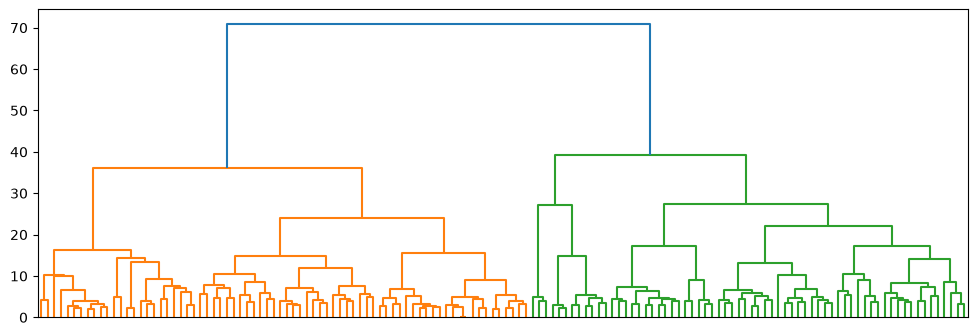

[(np.int32(1), 11), (np.int32(2), 13), (np.int32(3), 27), (np.int32(4), 10), (np.int32(5), 13), (np.int32(6), 3), (np.int32(7), 3), (np.int32(8), 6), (np.int32(9), 11), (np.int32(10), 5), (np.int32(11), 18), (np.int32(12), 7), (np.int32(13), 13)]


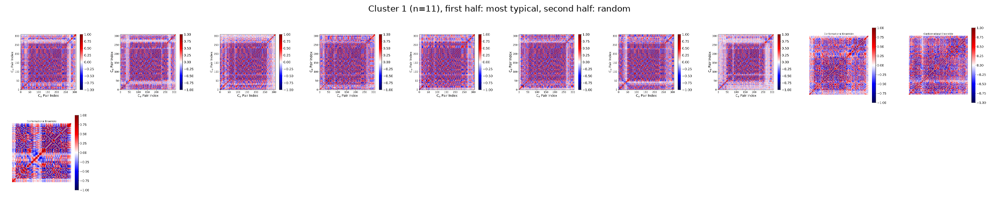

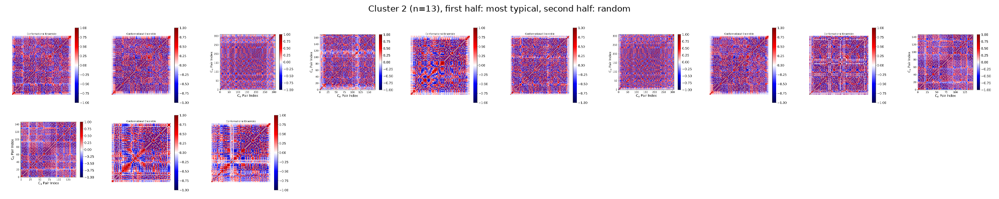

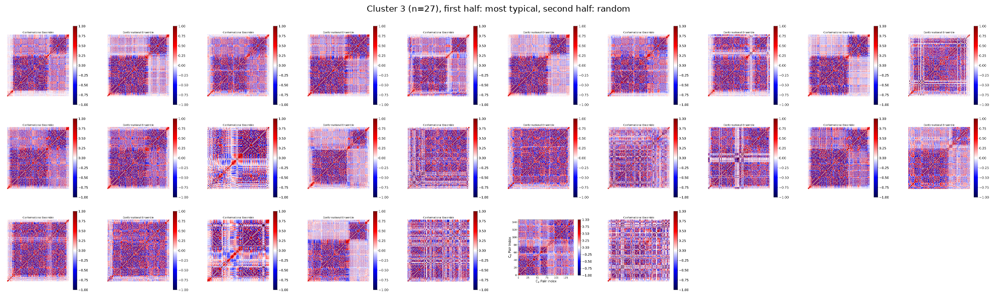

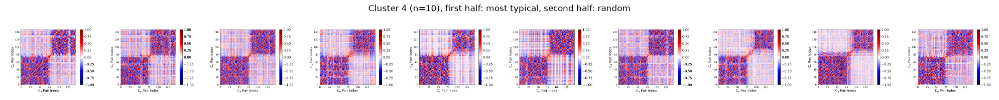

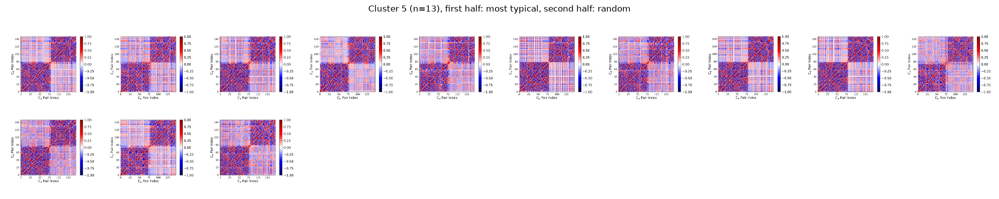

...

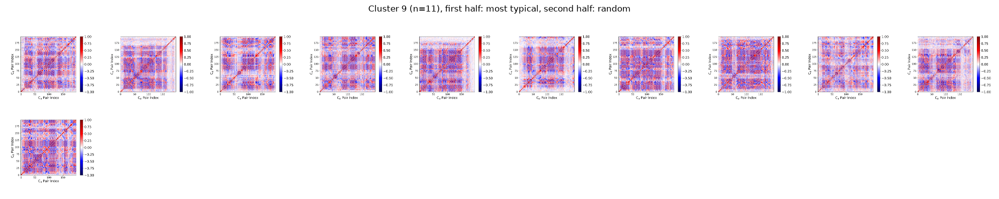

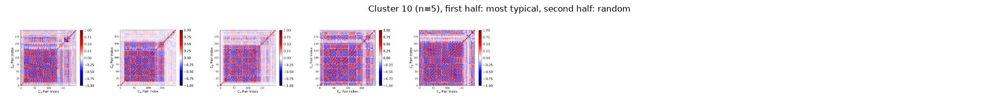

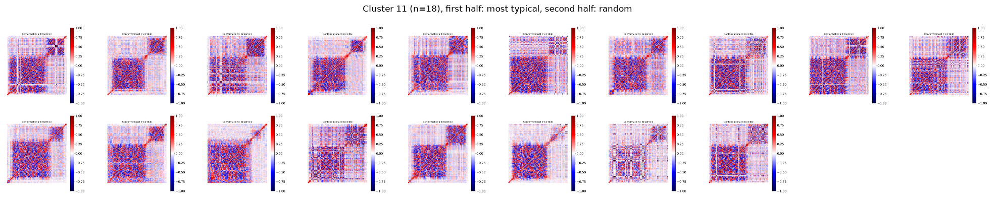

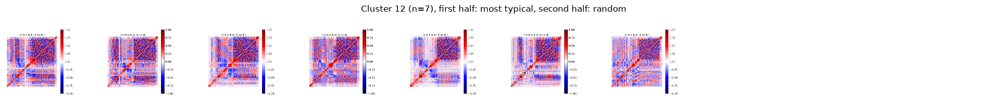

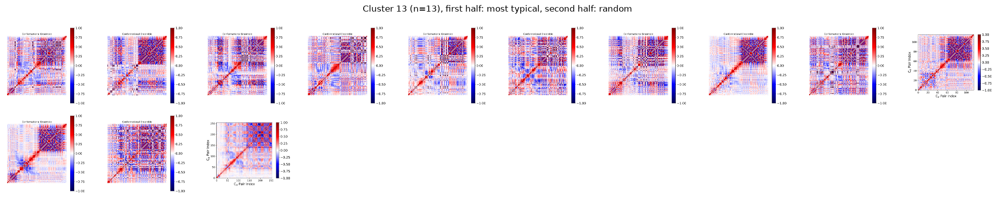


=== Cluster 1 (n=11) ===
   KEA3_RCT_WT_apo_repeat_05   [FF: CHARMM36m]
   KEA3_RCT_WT_apo_repeat_06   [FF: CHARMM36m]
   KEA3_RCT_WT_apo_repeat_01   [FF: CHARMM36m]
   KEA3_RCT_WT_apo_repeat_03   [FF: CHARMM36m]
   KEA3_RCT_WT_apo_repeat_02   [FF: CHARMM36m]
   KEA3_RCT_WT_apo_repeat_07   [FF: CHARMM36m]
   KEA3_RCT_WT_apo_repeat_09   [FF: CHARMM36m]
   KEA3_RCT_WT_apo_repeat_08   [FF: CHARMM36m]
   MANF   [FF: amber99SB-ILDN]
   MANF   [FF: amber99SB-ILDN]
   EN2   [FF: amber99SB-ILDN]

=== Cluster 2 (n=13) ===
   CDNF   [FF: DESamber]
   CDNF   [FF: amber99SB-disp]
   KEA3_RCT_WT_apo_repeat_00   [FF: CHARMM36m]
   MANF   [FF: amber99SB-ILDN]
   EN2   [FF: amber99SB-ILDN]
   CDNF   [FF: amber99SB-ILDN]
   KEA3_RCT_WT_apo_repeat_04   [FF: CHARMM36m]
   CDNF   [FF: DESamber]
   CDNF   [FF: amber99SB-ILDN]
   calmodulin   [FF: amber99SB-disp]
   calmodulin   [FF: amber99SB-disp]
   EN2   [FF: amber99SB-disp]
   EN2   [FF: amber99SB-ILDN]

=== Cluster 3 (n=27) ===
   MANF   [FF: amber99

In [4]:
import numpy as np
import pandas as pd
from collections import Counter, defaultdict
from tqdm.auto import tqdm
from PIL import Image
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.preprocessing import StandardScaler

MIN_N = 4
CSV_NAME = 'Backbone_correlations.csv'
PNG_NAME = 'Backbone_correlations.png'

# ---------- loading ----------
def load_matrix(path):
    M = np.atleast_2d(np.loadtxt(path, delimiter=','))
    if M.ndim != 2 or M.shape[0] != M.shape[1]:
        raise ValueError(f'not square: {M.shape}')
    if not np.isfinite(M).all():
        raise ValueError('contains NaN/inf')
    M = (M + M.T) / 2
    np.fill_diagonal(M, 1.0)
    return M

mats, paths_png, names, ffs, skipped = [], [], [], [], []
for system in tqdm(systems, desc='Loading CSVs', unit='sys'):
    base = databankPath + 'Data/Simulations/' + system['path']
    if system['SYSTEM'] not in curated_list_of_partially_folded_proteins:
        continue
    try:
        M = load_matrix(base + CSV_NAME)
        if M.shape[0] < MIN_N:
            raise ValueError(f'matrix too small: {M.shape}')
        mats.append(M)
        paths_png.append(base + PNG_NAME)
        names.append(system['SYSTEM'])
        ffs.append(system.get('FF', ''))
    except (FileNotFoundError, ValueError) as e:
        skipped.append((base, f'{type(e).__name__}: {e}'))

print(f'{len(mats)} loaded, {len(skipped)} skipped')
for msg, n in Counter(e for _, e in skipped).most_common(5):
    print(n, 'x', msg)
sizes = np.array([len(M) for M in mats])
print('sizes: min', sizes.min(), 'median', int(np.median(sizes)), 'max', sizes.max())

# ---------- descriptors ----------
def descriptors(M, nhist=20, nsep=10, neig=8, use_size=False):
    N = len(M); iu = np.triu_indices(N, 1); off = M[iu]
    sep = np.abs(np.subtract.outer(np.arange(N), np.arange(N)))[iu]

    hist = np.histogram(off, bins=nhist, range=(-1, 1))[0] / len(off)

    b = np.minimum((sep / (N - 1) * nsep).astype(int), nsep - 1)
    prof = np.bincount(b, off, nsep) / np.maximum(np.bincount(b, minlength=nsep), 1)

    w = np.clip(np.linalg.eigvalsh(M)[::-1], 0, None); w = w / w.sum()
    eig = np.pad(w[:neig], (0, max(0, neig - len(w))))

    lags = (1, 2, 3, 5, 8, 12)
    lagmean = [np.diag(M, k).mean() if k < N else 0.0 for k in lags]
    lagabs  = [np.abs(np.diag(M, k)).mean() if k < N else 0.0 for k in lags]

    rough = [np.abs(np.diff(M, axis=0)).mean(), np.abs(np.diff(M, axis=1)).mean()]

    far = sep > 10
    longrange = [np.abs(off[far]).mean() if far.any() else 0.0,
                 off.mean(), off.std(),
                 np.abs(off).mean(), (off > .3).mean(), (off < -.3).mean()]

    d = np.concatenate([hist, prof, eig, lagmean, lagabs, rough, longrange])
    return np.append(d, np.log(N)) if use_size else d

# ---------- clustering ----------
D = np.array([descriptors(M) for M in tqdm(mats, desc='Descriptors')])
X = StandardScaler().fit_transform(D)
Z = linkage(X, 'ward')

plt.figure(figsize=(12, 4)); dendrogram(Z, no_labels=True); plt.show()

K = 13   # tune using the dendrogram and the gallery
labels = fcluster(Z, K, 'maxclust')
print(sorted(Counter(labels).items()))

# ---------- gallery ----------
def gallery(paths, X, labels, per=30, ncols=10, seed=0):
    rng = np.random.default_rng(seed)
    for c in sorted(set(labels)):
        ids = np.where(labels == c)[0]
        order = ids[np.argsort(np.linalg.norm(X[ids] - X[ids].mean(0), axis=1))]
        head = list(order[:per // 2])
        rest = order[per // 2:]
        tail = list(rng.choice(rest, min(per - len(head), len(rest)), replace=False)) if len(rest) else []
        show = head + tail

        nrows = int(np.ceil(len(show) / ncols))
        fig, axs = plt.subplots(nrows, ncols, figsize=(2.0 * ncols, 2.0 * nrows), squeeze=False)
        for a in axs.ravel():
            a.axis('off')
        for a, i in zip(axs.ravel(), show):
            a.imshow(Image.open(paths[i]))
        fig.suptitle(f'Cluster {c} (n={len(ids)}), first half: most typical, second half: random')
        plt.tight_layout()
        plt.show()

gallery(paths_png, X, labels, per=30, ncols=10)

# ---------- list SYSTEM and FF per cluster ----------
def list_systems(names, ffs, labels, X=None):
    """Print SYSTEM and FF for each cluster; with X, most typical members come first."""
    clusters = defaultdict(list)
    for i, c in enumerate(labels):
        clusters[c].append(i)
    for c in sorted(clusters):
        ids = np.array(clusters[c])
        if X is not None:
            ids = ids[np.argsort(np.linalg.norm(X[ids] - X[ids].mean(0), axis=1))]
        print(f'\n=== Cluster {c} (n={len(ids)}) ===')
        for i in ids:
            print(f'   {names[i]}   [FF: {ffs[i]}]')

list_systems(names, ffs, labels, X)

# ---------- save to CSV ----------
df = pd.DataFrame({'SYSTEM': names, 'FF': ffs, 'cluster': labels,
                   'N': sizes, 'png': paths_png})
df.sort_values(['cluster', 'SYSTEM']).to_csv('clusters.csv', index=False)
print('\nSaved clusters.csv')

# ---------- optional: force field composition of each cluster ----------
print(pd.crosstab(df['cluster'], df['FF']))

'amberff03ws' <- {'AMBER03WS': 6, 'amberff03ws': 23}
'amber99SB-disp' <- {'amber99SB-disp': 20, 'AMBER99SB-DISP': 5}
'amber99SBws' <- {'amber99SBws': 19, 'AMBER99SBws': 1, 'AMBER99SBWS': 5}
'CHARMM36m' <- {'CHARMM36m': 10, 'CHARMM36M': 5}
'DESamber' <- {'DESamber': 21, 'DESAMBER': 5}


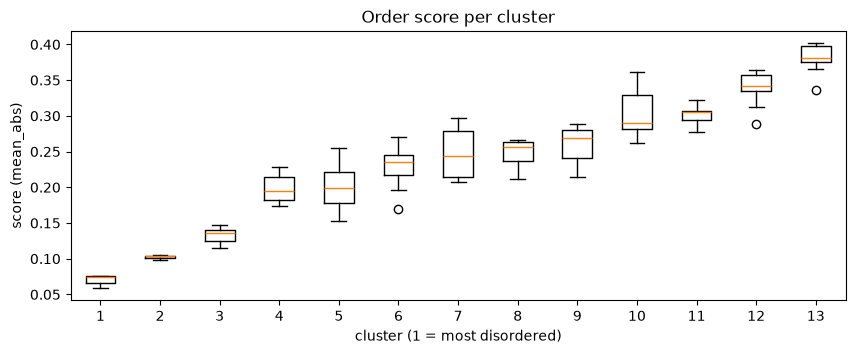

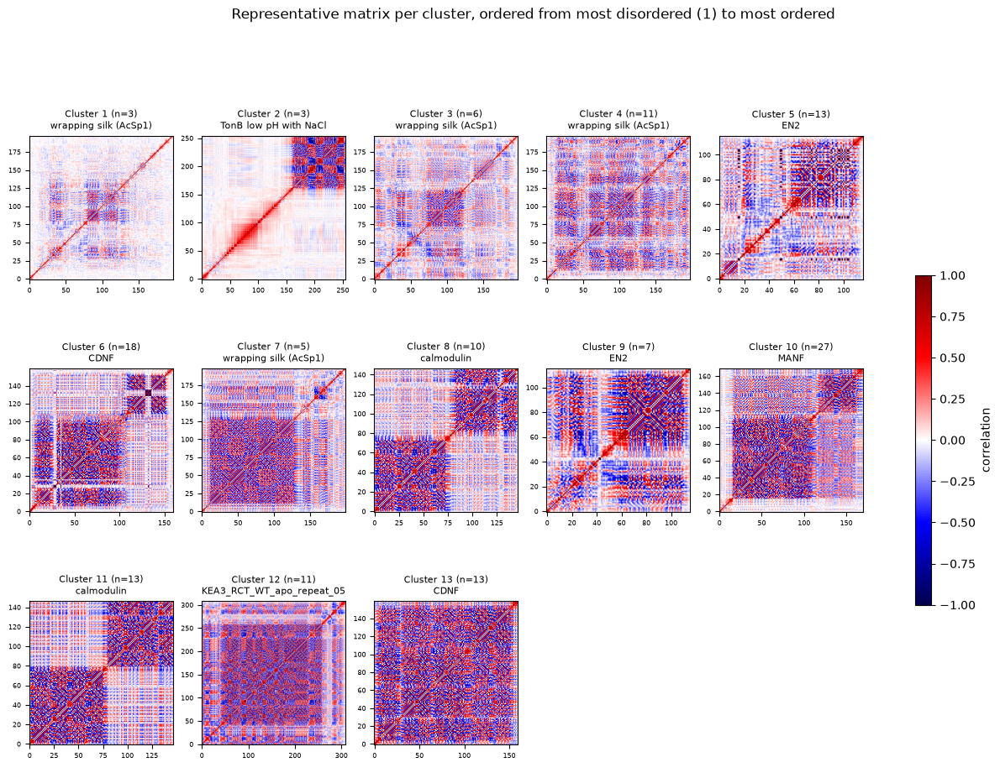

 cluster  old_cluster  n  median_score     representative_SYSTEM representative_FF
       1            7  3      0.073929     wrapping silk (AcSp1)       amber99SBws
       2            6  3      0.103125     TonB low pH with NaCl       amberff03ws
       3            8  6      0.135317     wrapping silk (AcSp1)       amberff03ws
       4            9 11      0.195400     wrapping silk (AcSp1)    amber99SB-disp
       5           13 13      0.198529                       EN2       amberff03ws
       6           11 18      0.234969                      CDNF       amber99SBws
       7           10  5      0.244127     wrapping silk (AcSp1)    amber99SB-disp
       8            4 10      0.256689                calmodulin       amberff03ws
       9           12  7      0.269639                       EN2       amber99SBws
      10            3 27      0.289692                      MANF    amber99SB-disp
      11            5 13      0.305279                calmodulin    amber99SB-disp
    

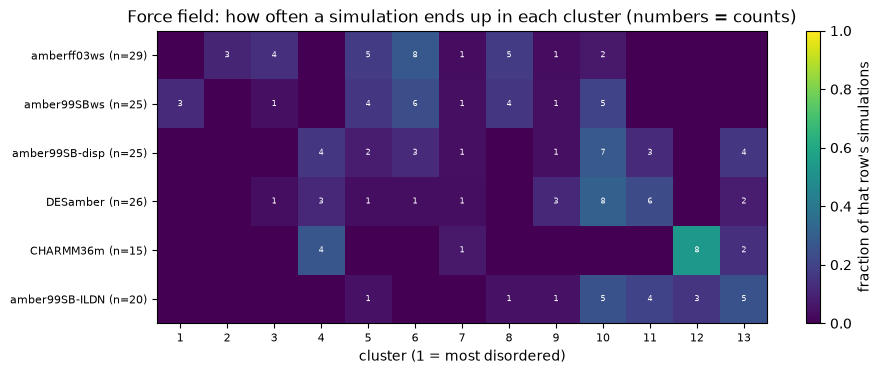

cluster         1   2   3   4   5   6   7   8   9   10  11  12  13
FF                                                                
amberff03ws      0  10  14   0  17  28   3  17   3   7   0   0   0
amber99SBws     12   0   4   0  16  24   4  16   4  20   0   0   0
amber99SB-disp   0   0   0  16   8  12   4   0   4  28  12   0  16
DESamber         0   0   4  12   4   4   4   0  12  31  23   0   8
CHARMM36m        0   0   0  27   0   0   7   0   0   0   0  53  13
amber99SB-ILDN   0   0   0   0   5   0   0   5   5  25  20  15  25
                              n_sims  n_clusters_used  top_cluster  top_share
SYSTEM                                                                       
CDNF                              25                3           10       0.48
EN2                               25                5            5       0.48
calmodulin                        25                4           11       0.48
wrapping silk (AcSp1)             25                4            4       0

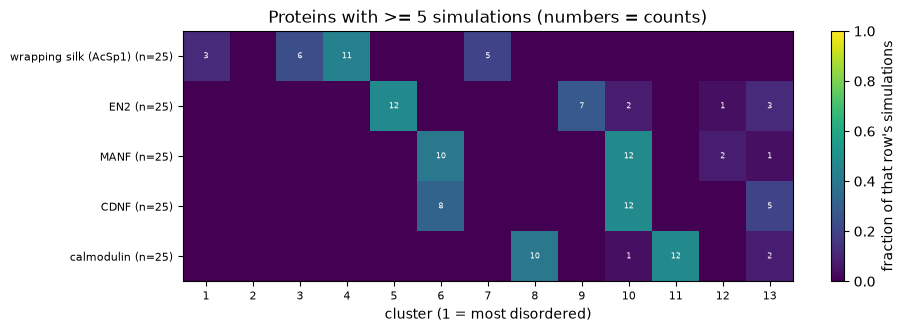

Saved partial_clusters_final.csv


In [5]:
import re
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter

# ---------- settings ----------
PREFIX           = 'partial_'      # output file prefix
labels_in        = np.asarray(labels).copy()   # use your refined labels here if you split clusters further
ORDER_BY         = 'mean_abs'      # disorder measure: 'mean_abs', 'p99' or 'top_eig'
MIN_SEP          = 5               # ignore the near-diagonal band |i-j| < MIN_SEP
MIN_SIMS_PROTEIN = 5               # proteins with fewer simulations are left out of the heatmap
MANUAL_ORDER     = None            # optional: list of current cluster ids, most disordered first
ALIASES          = {}              # extra FF merges, normalised form, e.g. {'c36m': 'charmm36m'}

# ---------- merge force field spelling variants ----------
def ff_key(s):
    k = re.sub(r'[^a-z0-9]', '', str(s).lower())
    k = k.replace('amberff', 'amber')
    return ALIASES.get(k, k)

spellings = {}
for f in ffs:
    spellings.setdefault(ff_key(f), Counter())[f] += 1
display = {k: c.most_common(1)[0][0] for k, c in spellings.items()}
for k, c in sorted(spellings.items()):
    if len(c) > 1:
        print(f'{display[k]!r} <- {dict(c)}')
ffs_m = [display[ff_key(f)] for f in ffs]

# ---------- 4) order clusters from most disordered to most ordered ----------
def order_score(M):
    if ORDER_BY == 'top_eig':
        return np.linalg.eigvalsh(M)[-1] / len(M)
    N = len(M); iu = np.triu_indices(N, 1)
    sep = np.abs(np.subtract.outer(np.arange(N), np.arange(N)))[iu]
    v = np.abs(M[iu])[sep >= MIN_SEP]
    if len(v) == 0:
        return 0.0
    return v.mean() if ORDER_BY == 'mean_abs' else np.percentile(v, 99)

score = np.array([order_score(M) for M in mats])
old_ids = np.unique(labels_in)
cl_score = {c: np.median(score[labels_in == c]) for c in old_ids}

if MANUAL_ORDER is None:
    ordered_old = sorted(old_ids, key=lambda c: cl_score[c])    # low score = disordered
else:
    ordered_old = list(MANUAL_ORDER)
    assert set(ordered_old) == set(old_ids), 'MANUAL_ORDER must list every cluster once'

rank = {c: i + 1 for i, c in enumerate(ordered_old)}
final = np.array([rank[c] for c in labels_in])       # cluster 1 = most disordered
clusters = list(range(1, len(ordered_old) + 1))

df = pd.DataFrame({'SYSTEM': names, 'FF': ffs_m, 'cluster': final,
                   'old_cluster': labels_in, 'N': sizes, 'score': score, 'png': paths_png})

plt.figure(figsize=(10, 3.5))
plt.boxplot([score[final == k] for k in clusters], showfliers=True)
plt.xticks(range(1, len(clusters) + 1), clusters)
plt.xlabel('cluster (1 = most disordered)'); plt.ylabel(f'score ({ORDER_BY})')
plt.title('Order score per cluster'); plt.show()

# ---------- 3) representative figure of each cluster ----------
rep = {}
for k in clusters:
    ids = np.where(final == k)[0]
    rep[k] = ids[np.argmin(np.linalg.norm(X[ids] - X[ids].mean(0), axis=1))]

ncols = 5
nrows = int(np.ceil(len(clusters) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.4 * nrows), squeeze=False)
for a in axs.ravel():
    a.axis('off')
for a, k in zip(axs.ravel(), clusters):
    i = rep[k]
    im = a.imshow(mats[i], cmap='seismic', vmin=-1, vmax=1, origin='lower')
    a.axis('on'); a.tick_params(labelsize=6)
    a.set_title(f'Cluster {k} (n={(final == k).sum()})\n{names[i]}', fontsize=8)
fig.suptitle('Representative matrix per cluster, ordered from most disordered (1) to most ordered', y=1.0)
fig.colorbar(im, ax=axs.ravel().tolist(), shrink=0.5, label='correlation')
fig.savefig(PREFIX + 'cluster_representatives.png', dpi=200, bbox_inches='tight')
plt.show()

summary = pd.DataFrame({
    'cluster': clusters,
    'old_cluster': ordered_old,
    'n': [(final == k).sum() for k in clusters],
    'median_score': [np.median(score[final == k]) for k in clusters],
    'representative_SYSTEM': [names[rep[k]] for k in clusters],
    'representative_FF': [ffs_m[rep[k]] for k in clusters],
})
print(summary.to_string(index=False))
summary.to_csv(PREFIX + 'cluster_summary.csv', index=False)

# ---------- heatmap helper ----------
def heat(cnt, frac, title, fname, figsize):
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(frac.values, aspect='auto', cmap='viridis', vmin=0, vmax=1)
    ax.set_xticks(range(len(frac.columns))); ax.set_xticklabels(frac.columns, fontsize=8)
    ax.set_yticks(range(len(frac.index)))
    ax.set_yticklabels([f'{r} (n={int(cnt.loc[r].sum())})' for r in frac.index], fontsize=8)
    ax.set_xlabel('cluster (1 = most disordered)')
    for r in range(cnt.shape[0]):
        for c in range(cnt.shape[1]):
            n = cnt.values[r, c]
            if n > 0:
                ax.text(c, r, int(n), ha='center', va='center', fontsize=6,
                        color='white' if frac.values[r, c] < 0.6 else 'black')
    fig.colorbar(im, ax=ax, label="fraction of that row's simulations")
    ax.set_title(title)
    fig.savefig(fname, dpi=200, bbox_inches='tight')
    plt.show()

# ---------- 1) force field vs cluster ----------
ct_ff = pd.crosstab(df['FF'], df['cluster']).reindex(columns=clusters, fill_value=0)
fr_ff = ct_ff.div(ct_ff.sum(axis=1), axis=0)
ct_ff = ct_ff.loc[(fr_ff * clusters).sum(axis=1).sort_values().index]
fr_ff = fr_ff.loc[ct_ff.index]

heat(ct_ff, fr_ff, 'Force field: how often a simulation ends up in each cluster (numbers = counts)',
     PREFIX + 'ff_vs_cluster.png', (0.45 * len(clusters) + 4, 0.3 * len(ct_ff) + 2))
ct_ff.to_csv(PREFIX + 'ff_vs_cluster_counts.csv')
(fr_ff * 100).round(1).to_csv(PREFIX + 'ff_vs_cluster_percent.csv')
print((fr_ff * 100).round(0).astype(int).to_string())

# ---------- 2) protein (SYSTEM) vs cluster ----------
ct_pr = pd.crosstab(df['SYSTEM'], df['cluster']).reindex(columns=clusters, fill_value=0)
fr_pr = ct_pr.div(ct_pr.sum(axis=1), axis=0)
ct_pr.to_csv(PREFIX + 'protein_vs_cluster_counts.csv')
(fr_pr * 100).round(1).to_csv(PREFIX + 'protein_vs_cluster_percent.csv')

prot = pd.DataFrame({
    'n_sims': ct_pr.sum(axis=1),
    'n_clusters_used': (ct_pr > 0).sum(axis=1),
    'top_cluster': ct_pr.idxmax(axis=1),
    'top_share': fr_pr.max(axis=1).round(2),
}).sort_values('n_sims', ascending=False)
prot.to_csv(PREFIX + 'protein_consistency.csv')
print(prot.head(20).to_string())

keep = ct_pr.index[ct_pr.sum(axis=1) >= MIN_SIMS_PROTEIN]
if len(keep):
    ct_k, fr_k = ct_pr.loc[keep], fr_pr.loc[keep]
    order = (fr_k * clusters).sum(axis=1).sort_values().index
    ct_k, fr_k = ct_k.loc[order], fr_k.loc[order]
    heat(ct_k, fr_k, f'Proteins with >= {MIN_SIMS_PROTEIN} simulations (numbers = counts)',
         PREFIX + 'protein_vs_cluster.png',
         (0.45 * len(clusters) + 4, min(0.25 * len(ct_k) + 2, 40)))
else:
    print(f'No protein has >= {MIN_SIMS_PROTEIN} simulations; see {PREFIX}protein_vs_cluster_*.csv')

# ---------- save everything in one table ----------
df.sort_values(['cluster', 'SYSTEM']).to_csv(PREFIX + 'clusters_final.csv', index=False)
print('Saved', PREFIX + 'clusters_final.csv')

# Clustering unfolded proteins

Loading CSVs:   0%|          | 0/495 [00:00<?, ?sys/s]

328 loaded, 0 skipped
sizes: min 8 median 71 max 205


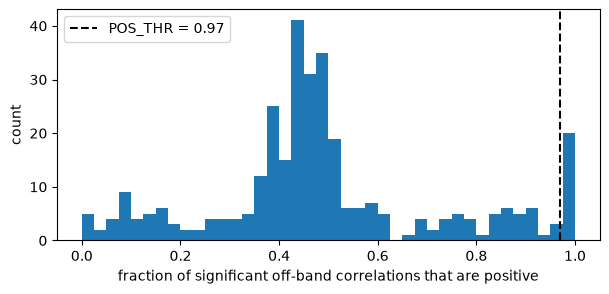

20 of 328 systems are positive-dominated


Descriptors:   0%|          | 0/328 [00:00<?, ?it/s]

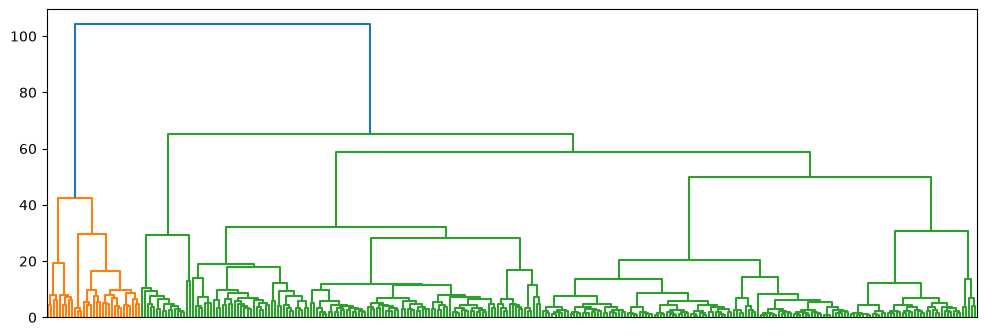

[(np.int64(1), 4), (np.int64(2), 5), (np.int64(3), 3), (np.int64(4), 19), (np.int64(5), 15), (np.int64(6), 2), (np.int64(7), 7), (np.int64(8), 19), (np.int64(9), 13), (np.int64(10), 62), (np.int64(11), 15), (np.int64(12), 63), (np.int64(13), 39), (np.int64(14), 37), (np.int64(15), 5), (np.int64(16), 20)] (cluster 16 = positive-dominated)


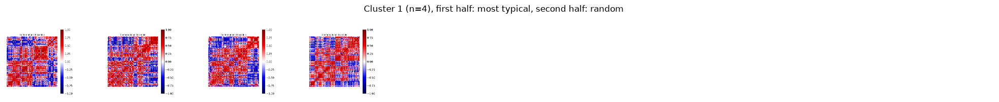

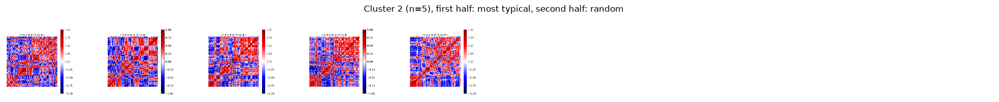

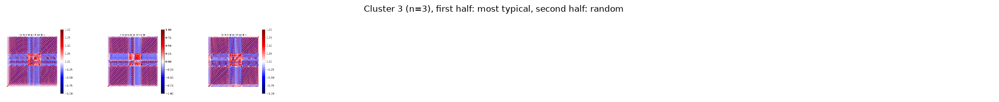

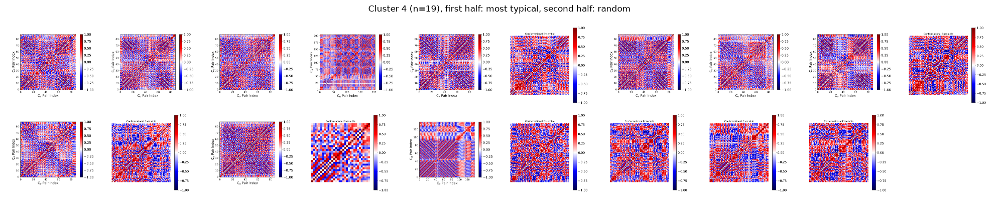

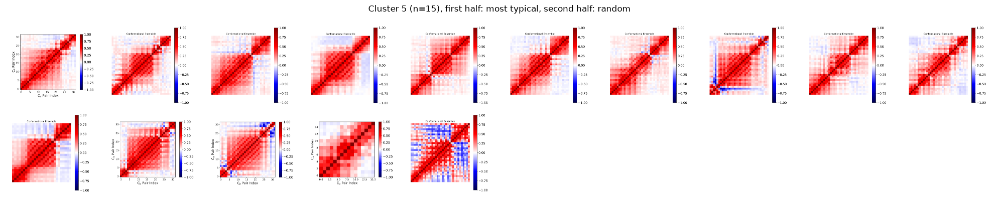

...

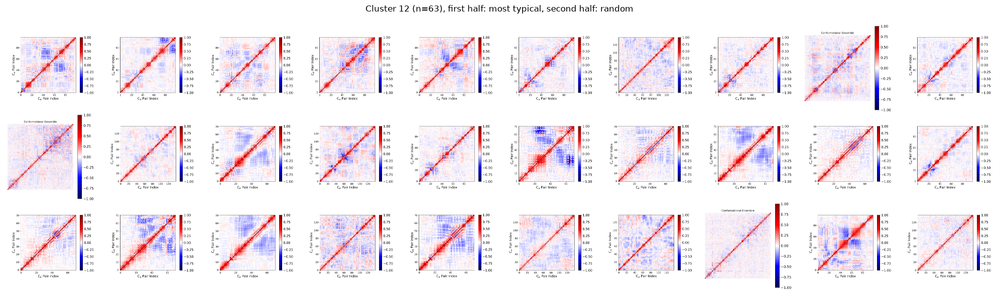

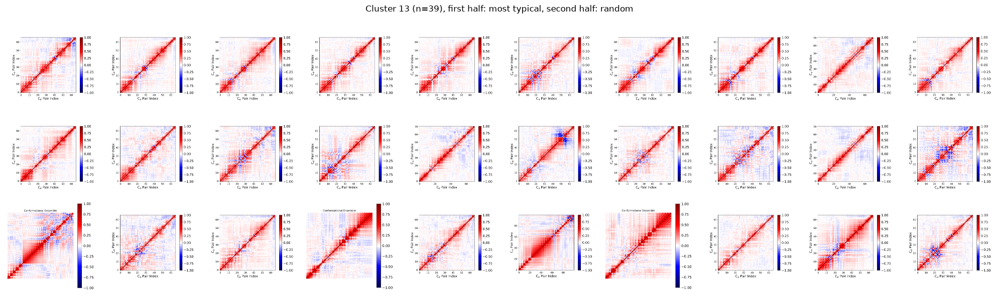

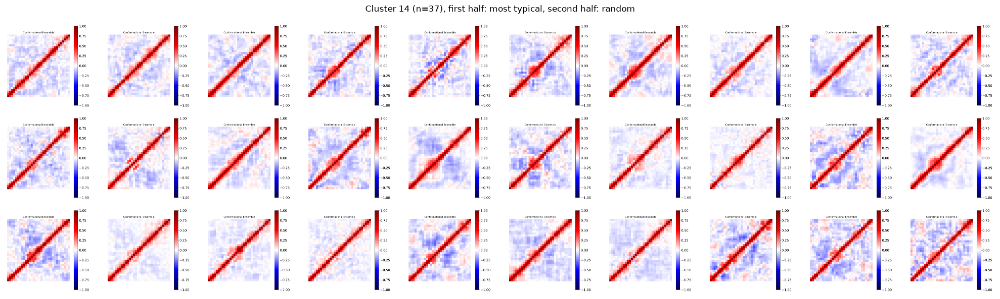

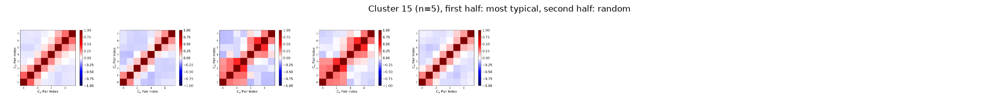

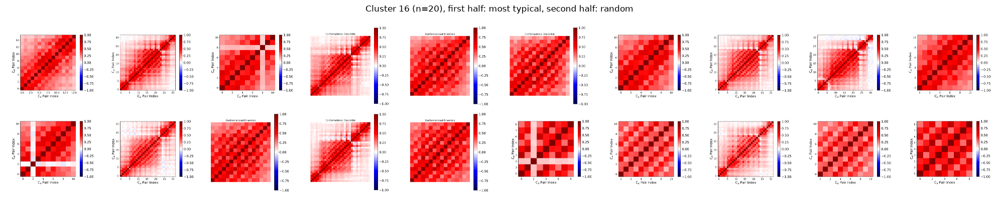


=== Cluster 1 (n=4) ===
   silk protein   [FF: AMBER03WS]
   silk protein   [FF: AMBER99SB-DISP]
   silk protein   [FF: DESAMBER]
   silk protein   [FF: CHARMM36M]

=== Cluster 2 (n=5) ===
   silk protein   [FF: AMBER99SB-DISP]
   silk protein   [FF: AMBER99SBWS]
   silk protein   [FF: AMBER03WS]
   silk protein   [FF: DESAMBER]
   silk protein   [FF: CHARMM36M]

=== Cluster 3 (n=3) ===
   SNAP25_noions   [FF: AMBER99SB-DISP]
   SNAP25_noions   [FF: DESAMBER]
   SNAP25_noions   [FF: CHARMM36M]

=== Cluster 4 (n=19) ===
   COR15A_monomer_repeat_05   [FF: OPLS_AA]
   COR15A_monomer_repeat_00   [FF: OPLS_AA]
   COR15A_monomer_repeat_04   [FF: OPLS_AA]
   SNAP25_noions   [FF: CHARMM36M]
   COR15A_monomer_repeat_08   [FF: OPLS_AA]
   silk protein   [FF: CHARMM36M]
   COR15A_monomer_repeat_09   [FF: OPLS_AA]
   COR15A_monomer_repeat_06   [FF: OPLS_AA]
   COR15A_monomer_repeat_03   [FF: OPLS_AA]
   silk protein   [FF: AMBER99SB-DISP]
   COR15A_monomer_repeat_01   [FF: OPLS_AA]
   silk protei

In [6]:
import numpy as np
import pandas as pd
from collections import Counter, defaultdict
from tqdm.auto import tqdm
from PIL import Image
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.preprocessing import StandardScaler

MIN_N = 4
CSV_NAME = 'Backbone_correlations.csv'
PNG_NAME = 'Backbone_correlations.png'

# ---------- loading ----------
def load_matrix(path):
    M = np.atleast_2d(np.loadtxt(path, delimiter=','))
    if M.ndim != 2 or M.shape[0] != M.shape[1]:
        raise ValueError(f'not square: {M.shape}')
    if not np.isfinite(M).all():
        raise ValueError('contains NaN/inf')
    M = (M + M.T) / 2
    np.fill_diagonal(M, 1.0)
    return M

mats, paths_png, names, ffs, skipped = [], [], [], [], []
for system in tqdm(systems, desc='Loading CSVs', unit='sys'):
    base = databankPath + 'Data/Simulations/' + system['path']
    if system['SYSTEM'] not in curated_list_of_unfolded_proteins:
        continue
    try:
        M = load_matrix(base + CSV_NAME)
        if M.shape[0] < MIN_N:
            raise ValueError(f'matrix too small: {M.shape}')
        mats.append(M)
        paths_png.append(base + PNG_NAME)
        names.append(system['SYSTEM'])
        ffs.append(system.get('FF', ''))
    except (FileNotFoundError, ValueError) as e:
        skipped.append((base, f'{type(e).__name__}: {e}'))

print(f'{len(mats)} loaded, {len(skipped)} skipped')
for msg, n in Counter(e for _, e in skipped).most_common(5):
    print(n, 'x', msg)
sizes = np.array([len(M) for M in mats])
print('sizes: min', sizes.min(), 'median', int(np.median(sizes)), 'max', sizes.max())

# ---------- descriptors ----------
def descriptors(M, nhist=20, nsep=10, neig=8, use_size=False):
    N = len(M); iu = np.triu_indices(N, 1); off = M[iu]
    sep = np.abs(np.subtract.outer(np.arange(N), np.arange(N)))[iu]

    hist = np.histogram(off, bins=nhist, range=(-1, 1))[0] / len(off)

    b = np.minimum((sep / (N - 1) * nsep).astype(int), nsep - 1)
    prof = np.bincount(b, off, nsep) / np.maximum(np.bincount(b, minlength=nsep), 1)

    w = np.clip(np.linalg.eigvalsh(M)[::-1], 0, None); w = w / w.sum()
    eig = np.pad(w[:neig], (0, max(0, neig - len(w))))

    lags = (1, 2, 3, 5, 8, 12)
    lagmean = [np.diag(M, k).mean() if k < N else 0.0 for k in lags]
    lagabs  = [np.abs(np.diag(M, k)).mean() if k < N else 0.0 for k in lags]

    rough = [np.abs(np.diff(M, axis=0)).mean(), np.abs(np.diff(M, axis=1)).mean()]

    far = sep > 10
    longrange = [np.abs(off[far]).mean() if far.any() else 0.0,
                 off.mean(), off.std(),
                 np.abs(off).mean(), (off > .3).mean(), (off < -.3).mean()]

    d = np.concatenate([hist, prof, eig, lagmean, lagabs, rough, longrange])
    return np.append(d, np.log(N)) if use_size else d

# ---------- positive-correlation measure ----------
POS_THR = 0.97   # share of significant off-band entries that are positive; choose from the histogram
EPS     = 0.05   # |corr| below this is treated as zero (noise)
MIN_SEP = 5      # ignore the near-diagonal band |i-j| < MIN_SEP (always positive in any chain)

def positive_fraction(M, min_sep=MIN_SEP, eps=EPS):
    """Among entries with |corr| > eps beyond the diagonal band: fraction that are positive."""
    N = len(M); iu = np.triu_indices(N, 1)
    sep = np.abs(np.subtract.outer(np.arange(N), np.arange(N)))[iu]
    v = M[iu][sep >= min_sep]
    if len(v) == 0:                      # tiny matrix: fall back to all off-diagonal entries
        v = M[iu]
    v = v[np.abs(v) > eps]
    return (v > 0).mean() if len(v) else 0.0   # no significant correlation at all: not "positive"

P = np.array([positive_fraction(M) for M in mats])

plt.figure(figsize=(7, 3))
plt.hist(P, bins=40)
plt.axvline(POS_THR, color='k', ls='--', label=f'POS_THR = {POS_THR}')
plt.xlabel('fraction of significant off-band correlations that are positive'); plt.ylabel('count')
plt.legend(); plt.show()

is_pos = P >= POS_THR
print(f'{is_pos.sum()} of {len(P)} systems are positive-dominated')

# ---------- clustering ----------
D = np.array([descriptors(M) for M in tqdm(mats, desc='Descriptors')])

# cluster only the non-positive systems, standardised within that group
rest = np.where(~is_pos)[0]
X = np.zeros_like(D)
X[rest] = StandardScaler().fit_transform(D[rest])
if is_pos.any():
    X[is_pos] = StandardScaler().fit_transform(D[is_pos]) if is_pos.sum() > 1 else 0.0
Z = linkage(X[rest], 'ward')

plt.figure(figsize=(12, 4)); dendrogram(Z, no_labels=True); plt.show()

K = 15   # number of clusters for the non-positive systems; tune using dendrogram and gallery
labels = np.zeros(len(mats), dtype=int)
labels[rest] = fcluster(Z, K, 'maxclust')
POS_LABEL = K + 1
labels[is_pos] = POS_LABEL               # positive-dominated systems form their own cluster
print(sorted(Counter(labels).items()), f'(cluster {POS_LABEL} = positive-dominated)')

# ---------- gallery ----------
def gallery(paths, X, labels, per=30, ncols=10, seed=0):
    rng = np.random.default_rng(seed)
    for c in sorted(set(labels)):
        ids = np.where(labels == c)[0]
        order = ids[np.argsort(np.linalg.norm(X[ids] - X[ids].mean(0), axis=1))]
        head = list(order[:per // 2])
        rest_ = order[per // 2:]
        tail = list(rng.choice(rest_, min(per - len(head), len(rest_)), replace=False)) if len(rest_) else []
        show = head + tail

        nrows = int(np.ceil(len(show) / ncols))
        fig, axs = plt.subplots(nrows, ncols, figsize=(2.0 * ncols, 2.0 * nrows), squeeze=False)
        for a in axs.ravel():
            a.axis('off')
        for a, i in zip(axs.ravel(), show):
            a.imshow(Image.open(paths[i]))
        fig.suptitle(f'Cluster {c} (n={len(ids)}), first half: most typical, second half: random')
        plt.tight_layout()
        plt.show()

gallery(paths_png, X, labels, per=30, ncols=10)

# ---------- list SYSTEM and FF per cluster ----------
def list_systems(names, ffs, labels, X=None):
    """Print SYSTEM and FF for each cluster; with X, most typical members come first."""
    clusters = defaultdict(list)
    for i, c in enumerate(labels):
        clusters[c].append(i)
    for c in sorted(clusters):
        ids = np.array(clusters[c])
        if X is not None:
            ids = ids[np.argsort(np.linalg.norm(X[ids] - X[ids].mean(0), axis=1))]
        print(f'\n=== Cluster {c} (n={len(ids)}) ===')
        for i in ids:
            print(f'   {names[i]}   [FF: {ffs[i]}]')

list_systems(names, ffs, labels, X)

# ---------- save to CSV ----------
df = pd.DataFrame({'SYSTEM': names, 'FF': ffs, 'cluster': labels,
                   'pos_fraction': P, 'N': sizes, 'png': paths_png})
df.sort_values(['cluster', 'SYSTEM']).to_csv('clusters.csv', index=False)
print('\nSaved clusters.csv')

# ---------- optional: force field composition of each cluster ----------
print(pd.crosstab(df['cluster'], df['FF']))

# Create subclusters for most disordered ones

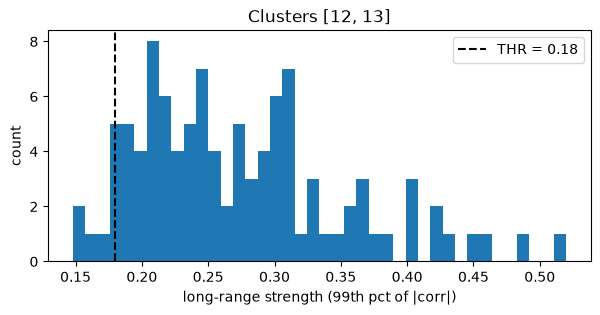

weak cluster 17: 6 of 102 matrices
[(np.int64(17), 6), (np.int64(18), 22), (np.int64(19), 15), (np.int64(20), 4), (np.int64(21), 8), (np.int64(22), 9), (np.int64(23), 4), (np.int64(24), 4), (np.int64(25), 4), (np.int64(26), 25), (np.int64(27), 1)]


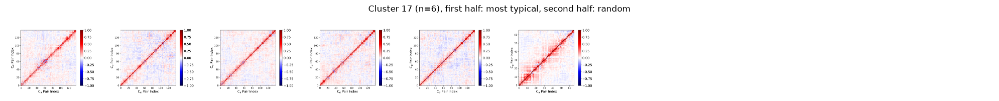

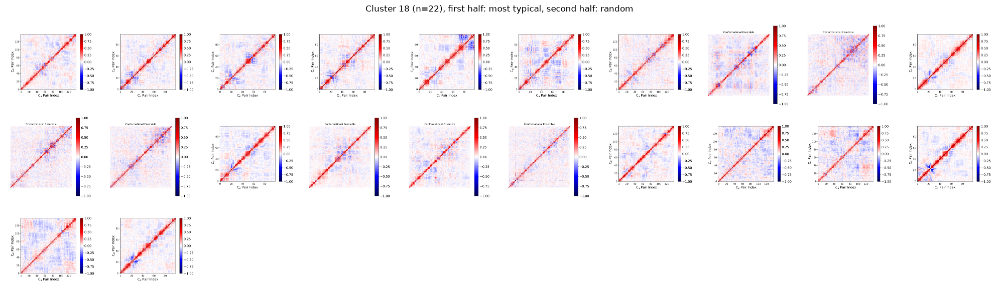

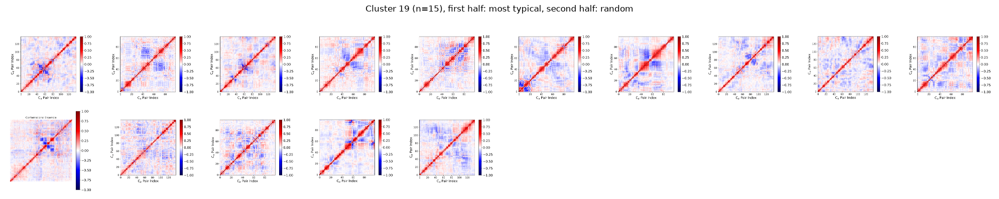

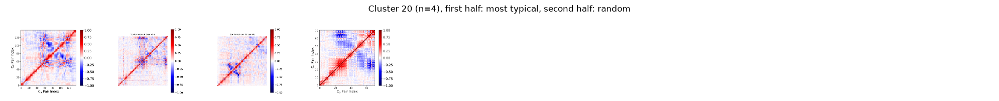

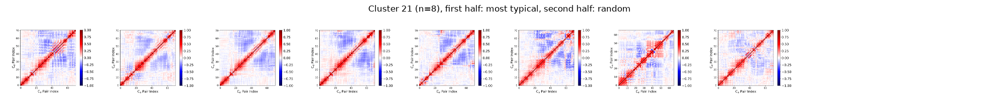

...

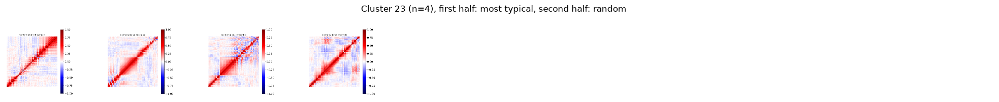

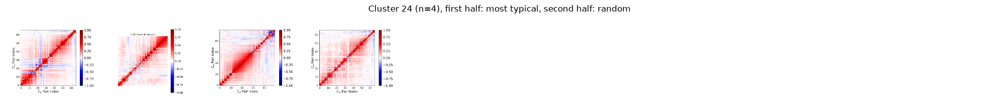

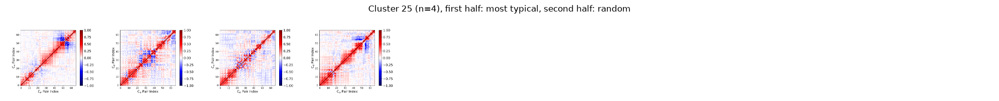

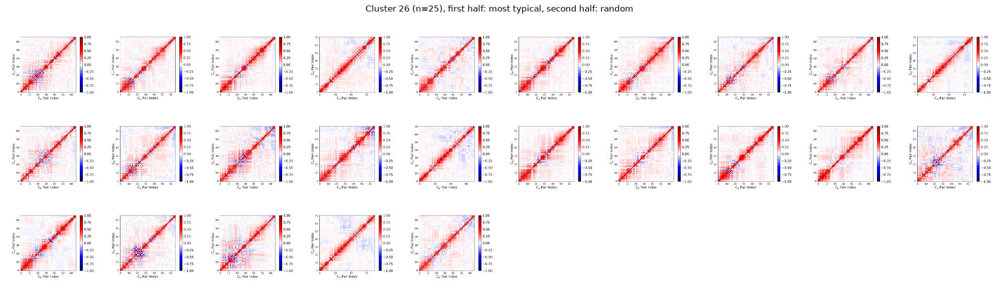

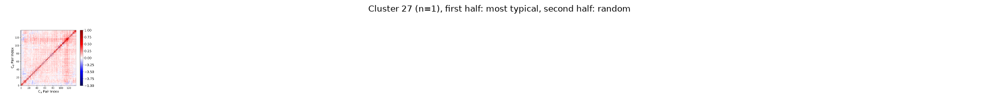


=== Cluster 17 (n=6) ===
   asyn_salt   [FF: AMBER99SBWS]
   asyn_salt   [FF: AMBER99SBWS]
   asyn_salt   [FF: AMBER99SBWS]
   asyn_salt   [FF: AMBER99SBWS]
   asyn_salt   [FF: AMBER99SBWS]
   ChiZ1-64   [FF: AMBER99SBWS]

=== Cluster 18 (n=22) ===
   asyn_salt   [FF: AMBER03WS]
   icl2   [FF: AMBER99SBWS]
   icl2   [FF: AMBER99SBWS]
   icl2   [FF: AMBER99SBWS]
   icl2   [FF: AMBER99SB-DISP]
   icl2   [FF: AMBER99SBWS]
   asyn_salt   [FF: AMBER99SB-DISP]
   SNAP25_noions   [FF: AMBER03WS]
   SNAP25_noions   [FF: AMBER99SBWS]
   icl2   [FF: AMBER03WS]
   SNAP25_noions   [FF: AMBER99SBWS]
   SNAP25_noions   [FF: AMBER99SBWS]
   icl2   [FF: AMBER03WS]
   SNAP25_noions   [FF: AMBER03WS]
   SNAP25_noions   [FF: AMBER03WS]
   icl2   [FF: AMBER03WS]
   asyn   [FF: AMBER99SBWS]
   asyn_salt   [FF: AMBER03WS]
   asyn   [FF: AMBER99SBWS]
   SNAP25_noions   [FF: AMBER99SBWS]
   icl2   [FF: AMBER03WS]
   asyn   [FF: AMBER99SBWS]

=== Cluster 19 (n=15) ===
   asyn_salt   [FF: AMBER03WS]
   icl2   

In [7]:
# ---------- refine clusters 6 and 7: weak cluster defined by 99th-percentile strength ----------
TARGETS = [12, 13]     # clusters to refine (check these match your current labels)
THR     = 0.18       # strength below this -> weak cluster; choose from the histogram
K_SUB   = 5          # number of sub-clusters for the remaining (stronger) matrices
JOINT   = False      # False: split 6 and 7 separately; True: pool them before splitting
MIN_SEP = 5          # ignore the near-diagonal band (|i-j| < MIN_SEP)
Q       = 99         # percentile of |corr| used as the strength measure

def strength(M, min_sep=MIN_SEP, q=Q):
    N = len(M); iu = np.triu_indices(N, 1)
    sep = np.abs(np.subtract.outer(np.arange(N), np.arange(N)))[iu]
    v = np.abs(M[iu])[sep >= min_sep]
    return np.percentile(v, q) if len(v) else 0.0

S = np.array([strength(M) for M in mats])
idx = np.where(np.isin(labels, TARGETS))[0]

plt.figure(figsize=(7, 3))
plt.hist(S[idx], bins=40)
plt.axvline(THR, color='k', ls='--', label=f'THR = {THR}')
plt.xlabel(f'long-range strength ({Q}th pct of |corr|)'); plt.ylabel('count')
plt.title(f'Clusters {TARGETS}'); plt.legend(); plt.show()

new = labels.copy()
next_label = labels.max() + 1

# 1) all weak matrices from the target clusters go into one cluster
weak = idx[S[idx] <= THR]
WEAK_LABEL = next_label; next_label += 1
new[weak] = WEAK_LABEL

# 2) re-cluster the remaining (stronger) ones, re-standardised within each group
groups = [TARGETS] if JOINT else [[c] for c in TARGETS]
for g in groups:
    strong = np.where(np.isin(labels, g) & (S > THR))[0]
    if len(strong) <= K_SUB:
        print(f'group {g}: only {len(strong)} strong matrices, left unsplit')
        continue
    Xs = StandardScaler().fit_transform(D[strong])
    sub = fcluster(linkage(Xs, 'ward'), K_SUB, 'maxclust')
    for s in np.unique(sub):
        new[strong[sub == s]] = next_label; next_label += 1

print(f'weak cluster {WEAK_LABEL}: {len(weak)} of {len(idx)} matrices')
print(sorted(Counter(new[idx]).items()))

# 3) inspect only the affected systems
changed = np.where(np.isin(new, np.unique(new[idx])))[0]
gallery([paths_png[i] for i in changed], X[changed], new[changed], per=30, ncols=10)
list_systems([names[i] for i in changed], [ffs[i] for i in changed], new[changed], X[changed])

# 4) save the full result
df = pd.DataFrame({'SYSTEM': names, 'FF': ffs, 'cluster': new,
                   'N': sizes, 'strength': S, 'png': paths_png})
df.sort_values(['cluster', 'SYSTEM']).to_csv('clusters_refined.csv', index=False)
print('Saved clusters_refined.csv')

# Order clusters based on correlations

In [8]:
import re
from collections import Counter

# Extra aliases, applied after the generic normalisation below.
# Keys and values are in normalised form: lowercase, no spaces, dashes or underscores.
ALIASES = {
    # 'charmm36m': 'charmm36mw',   # example of a manual merge
}

def ff_key(s):
    k = re.sub(r'[^a-z0-9]', '', str(s).lower())   # case, spaces, dashes, underscores
    k = k.replace('amberff', 'amber')              # amberff03ws -> amber03ws
    return ALIASES.get(k, k)

# Group the original spellings and use the most common one as the display name
spellings = {}
for f in ffs:
    spellings.setdefault(ff_key(f), Counter())[f] += 1
display = {k: c.most_common(1)[0][0] for k, c in spellings.items()}

# Show what was merged so you can check it
for k, c in sorted(spellings.items()):
    if len(c) > 1:
        print(f'{display[k]!r} <- {dict(c)}')

ffs = [display[ff_key(f)] for f in ffs]
print(f'\n{len(spellings)} distinct force fields after grouping')

'AMBER03WS' <- {'AMBER03WS': 54, 'Amberff03ws': 8, 'amberff03ws': 24}

7 distinct force fields after grouping


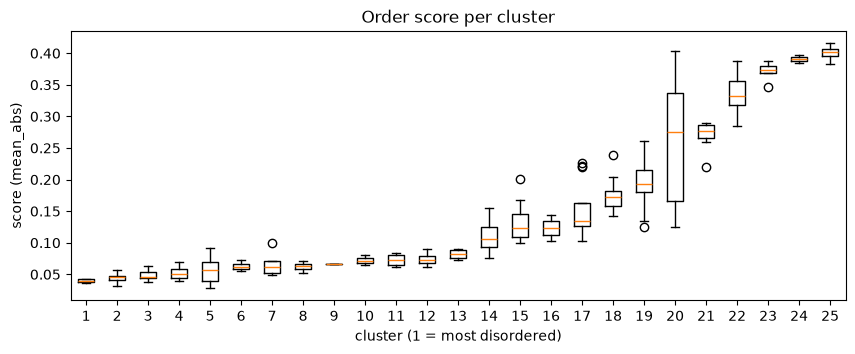

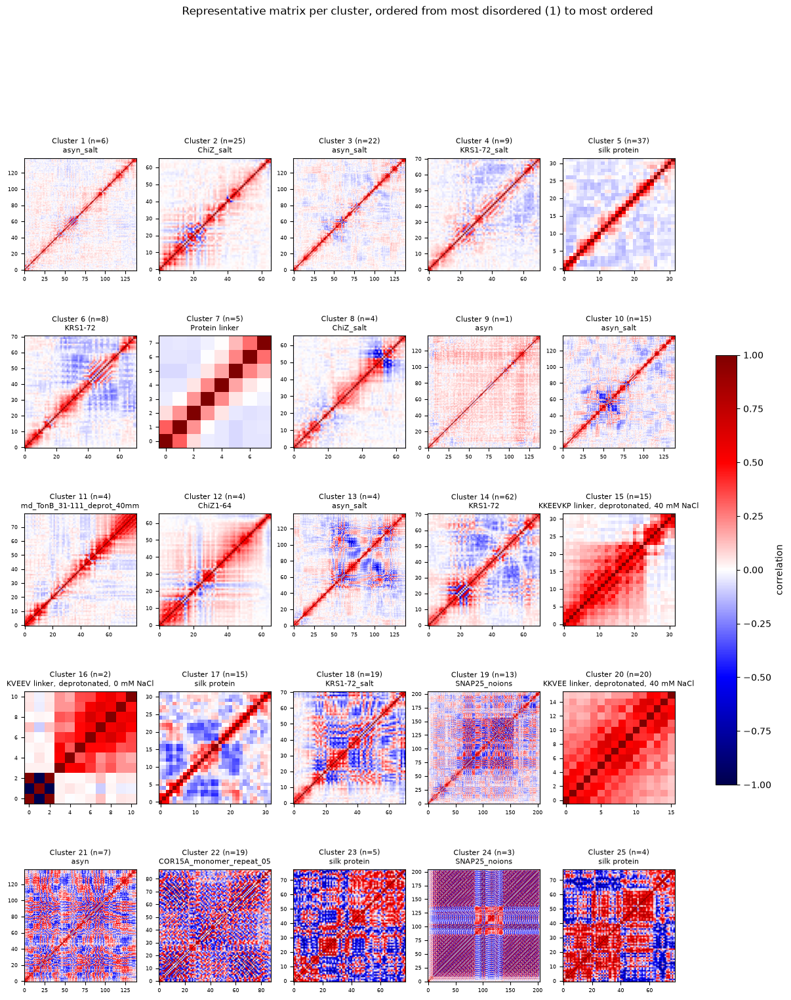

 cluster  old_cluster  n  median_score                    representative_SYSTEM representative_FF
       1           17  6      0.039953                                asyn_salt       AMBER99SBWS
       2           26 25      0.045342                                ChiZ_salt       AMBER99SBWS
       3           18 22      0.045930                                asyn_salt         AMBER03WS
       4           22  9      0.050937                             KRS1-72_salt       AMBER99SBWS
       5           14 37      0.056930                             silk protein       AMBER99SBWS
       6           21  8      0.061841                                  KRS1-72         AMBER03WS
       7           15  5      0.061866                           Protein linker          DESAMBER
       8           25  4      0.062720                                ChiZ_salt    AMBER99SB-DISP
       9           27  1      0.067027                                     asyn       AMBER99SBWS
      10           1

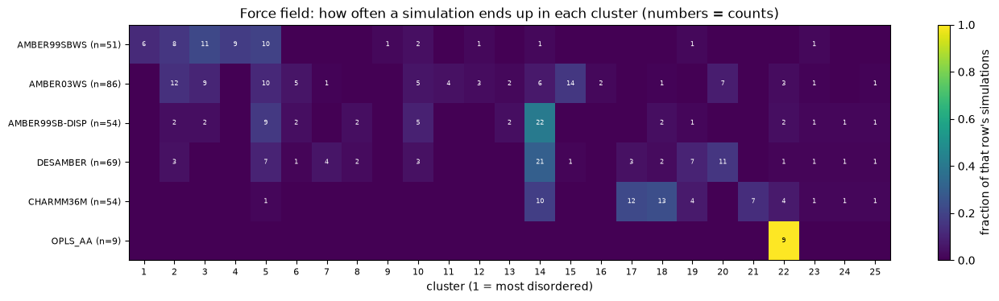

cluster         1   2   3   4   5   6   7   8   9   10  11  12  13  14  15  16  17  18  19  20  21   22  23  24  25
FF                                                                                                                 
AMBER99SBWS     12  16  22  18  20   0   0   0   2   4   0   2   0   2   0   0   0   0   2   0   0    0   2   0   0
AMBER03WS        0  14  10   0  12   6   1   0   0   6   5   3   2   7  16   2   0   1   0   8   0    3   1   0   1
AMBER99SB-DISP   0   4   4   0  17   4   0   4   0   9   0   0   4  41   0   0   0   4   2   0   0    4   2   2   2
DESAMBER         0   4   0   0  10   1   6   3   0   4   0   0   0  30   1   0   4   3  10  16   0    1   1   1   1
CHARMM36M        0   0   0   0   2   0   0   0   0   0   0   0   0  19   0   0  22  24   7   0  13    7   2   2   2
OPLS_AA          0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  100   0   0   0
                                          n_sims  n_clusters_used  top_c

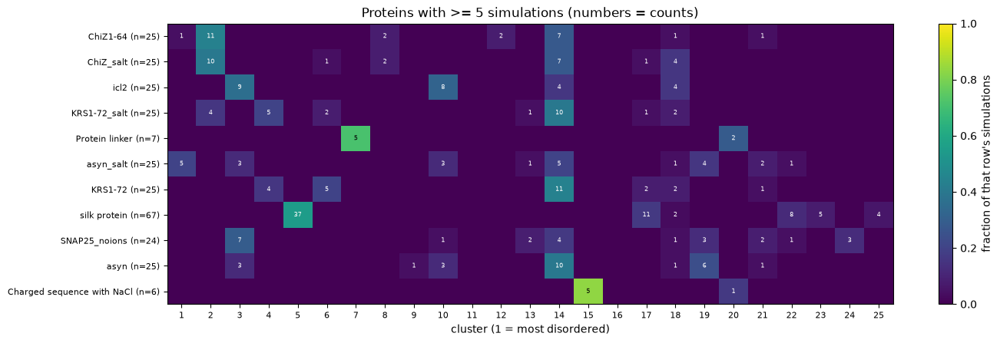

Saved clusters_final.csv


In [9]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# ---------- settings ----------
ORDER_BY         = 'mean_abs'  # disorder measure: 'mean_abs', 'p99' or 'top_eig' (see notes)
MIN_SEP          = 5           # ignore the near-diagonal band |i-j| < MIN_SEP
MIN_SIMS_PROTEIN = 5           # proteins with fewer simulations are left out of the heatmap
MANUAL_ORDER     = None        # optional: list of current cluster ids, most disordered first
labels_in        = new.copy()  # the 25 clusters from the previous step

# ---------- 4) order clusters from most disordered to most ordered ----------
def order_score(M):
    if ORDER_BY == 'top_eig':                     # share of variance in the dominant collective mode
        return np.linalg.eigvalsh(M)[-1] / len(M)
    N = len(M); iu = np.triu_indices(N, 1)
    sep = np.abs(np.subtract.outer(np.arange(N), np.arange(N)))[iu]
    v = np.abs(M[iu])[sep >= MIN_SEP]
    if len(v) == 0:
        return 0.0
    return v.mean() if ORDER_BY == 'mean_abs' else np.percentile(v, 99)

score = np.array([order_score(M) for M in mats])
old_ids = np.unique(labels_in)
cl_score = {c: np.median(score[labels_in == c]) for c in old_ids}

if MANUAL_ORDER is None:
    ordered_old = sorted(old_ids, key=lambda c: cl_score[c])   # low score = disordered
else:
    ordered_old = list(MANUAL_ORDER)
    assert set(ordered_old) == set(old_ids), 'MANUAL_ORDER must list every cluster once'

rank = {c: i + 1 for i, c in enumerate(ordered_old)}
final = np.array([rank[c] for c in labels_in])      # cluster 1 = most disordered
clusters = list(range(1, len(ordered_old) + 1))

df = pd.DataFrame({'SYSTEM': names, 'FF': ffs, 'cluster': final,
                   'old_cluster': labels_in, 'N': sizes, 'score': score, 'png': paths_png})

plt.figure(figsize=(10, 3.5))
#plt.boxplot([score[final == k] for k in clusters], labels=clusters, showfliers=True)
plt.boxplot([score[final == k] for k in clusters], tick_labels=clusters, showfliers=True)
plt.xlabel('cluster (1 = most disordered)'); plt.ylabel(f'score ({ORDER_BY})')
plt.title('Order score per cluster'); plt.show()

# ---------- 3) representative figure of each cluster ----------
# representative = member closest to the cluster centre in descriptor space (X)
rep = {}
for k in clusters:
    ids = np.where(final == k)[0]
    rep[k] = ids[np.argmin(np.linalg.norm(X[ids] - X[ids].mean(0), axis=1))]

ncols = 5
nrows = int(np.ceil(len(clusters) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.4 * nrows), squeeze=False)
for a in axs.ravel():
    a.axis('off')
for a, k in zip(axs.ravel(), clusters):
    i = rep[k]
    im = a.imshow(mats[i], cmap='seismic', vmin=-1, vmax=1, origin='lower')
    a.axis('on'); a.tick_params(labelsize=6)
    a.set_title(f'Cluster {k} (n={(final == k).sum()})\n{names[i]}', fontsize=8)
fig.suptitle('Representative matrix per cluster, ordered from most disordered (1) to most ordered', y=1.0)
fig.colorbar(im, ax=axs.ravel().tolist(), shrink=0.5, label='correlation')
fig.savefig('cluster_representatives.png', dpi=200, bbox_inches='tight')
plt.show()

summary = pd.DataFrame({
    'cluster': clusters,
    'old_cluster': ordered_old,
    'n': [(final == k).sum() for k in clusters],
    'median_score': [np.median(score[final == k]) for k in clusters],
    'representative_SYSTEM': [names[rep[k]] for k in clusters],
    'representative_FF': [ffs[rep[k]] for k in clusters],
})
print(summary.to_string(index=False))
summary.to_csv('cluster_summary.csv', index=False)

# ---------- heatmap helper ----------
def heat(cnt, frac, title, fname, figsize):
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(frac.values, aspect='auto', cmap='viridis', vmin=0, vmax=1)
    ax.set_xticks(range(len(frac.columns))); ax.set_xticklabels(frac.columns, fontsize=8)
    ax.set_yticks(range(len(frac.index)))
    ax.set_yticklabels([f'{r} (n={int(cnt.loc[r].sum())})' for r in frac.index], fontsize=8)
    ax.set_xlabel('cluster (1 = most disordered)')
    for r in range(cnt.shape[0]):
        for c in range(cnt.shape[1]):
            n = cnt.values[r, c]
            if n > 0:
                ax.text(c, r, int(n), ha='center', va='center', fontsize=6,
                        color='white' if frac.values[r, c] < 0.6 else 'black')
    fig.colorbar(im, ax=ax, label='fraction of that row\'s simulations')
    ax.set_title(title)
    fig.savefig(fname, dpi=200, bbox_inches='tight')
    plt.show()

# ---------- 1) force field vs cluster ----------
ct_ff = pd.crosstab(df['FF'], df['cluster']).reindex(columns=clusters, fill_value=0)
fr_ff = ct_ff.div(ct_ff.sum(axis=1), axis=0)
# sort force fields by their average cluster rank
ct_ff = ct_ff.loc[(fr_ff * clusters).sum(axis=1).sort_values().index]
fr_ff = fr_ff.loc[ct_ff.index]

heat(ct_ff, fr_ff, 'Force field: how often a simulation ends up in each cluster (numbers = counts)',
     'ff_vs_cluster.png', (0.45 * len(clusters) + 4, 0.3 * len(ct_ff) + 2))
ct_ff.to_csv('ff_vs_cluster_counts.csv')
(fr_ff * 100).round(1).to_csv('ff_vs_cluster_percent.csv')
print((fr_ff * 100).round(0).astype(int).to_string())

# ---------- 2) protein (SYSTEM) vs cluster ----------
ct_pr = pd.crosstab(df['SYSTEM'], df['cluster']).reindex(columns=clusters, fill_value=0)
fr_pr = ct_pr.div(ct_pr.sum(axis=1), axis=0)
ct_pr.to_csv('protein_vs_cluster_counts.csv')
(fr_pr * 100).round(1).to_csv('protein_vs_cluster_percent.csv')

# per-protein consistency: do all simulations of a protein land in the same cluster?
prot = pd.DataFrame({
    'n_sims': ct_pr.sum(axis=1),
    'n_clusters_used': (ct_pr > 0).sum(axis=1),
    'top_cluster': ct_pr.idxmax(axis=1),
    'top_share': fr_pr.max(axis=1).round(2),
}).sort_values('n_sims', ascending=False)
prot.to_csv('protein_consistency.csv')
print(prot.head(20).to_string())

# heatmap for proteins with enough simulations
keep = ct_pr.index[ct_pr.sum(axis=1) >= MIN_SIMS_PROTEIN]
if len(keep):
    ct_k, fr_k = ct_pr.loc[keep], fr_pr.loc[keep]
    order = (fr_k * clusters).sum(axis=1).sort_values().index
    ct_k, fr_k = ct_k.loc[order], fr_k.loc[order]
    heat(ct_k, fr_k, f'Proteins with >= {MIN_SIMS_PROTEIN} simulations (numbers = counts)',
         'protein_vs_cluster.png', (0.45 * len(clusters) + 4, min(0.25 * len(ct_k) + 2, 40)))
else:
    print(f'No protein has >= {MIN_SIMS_PROTEIN} simulations; see protein_vs_cluster_*.csv')

# ---------- save everything in one table ----------
df.sort_values(['cluster', 'SYSTEM']).to_csv('clusters_final.csv', index=False)
print('Saved clusters_final.csv')

# Find amino acids promoting positive correlation clusters

328 of 328 simulations have a sequence matching the matrix size
328 simulations with matching sequence -> 243 after excluding clusters [17, 18, 19, 21, 22, 23, 24, 25]
simulations per remaining cluster: {np.int64(1): np.int64(6), np.int64(2): np.int64(25), np.int64(3): np.int64(22), np.int64(4): np.int64(9), np.int64(5): np.int64(37), np.int64(6): np.int64(8), np.int64(7): np.int64(5), np.int64(8): np.int64(4), np.int64(9): np.int64(1), np.int64(10): np.int64(15), np.int64(11): np.int64(4), np.int64(12): np.int64(4), np.int64(13): np.int64(4), np.int64(14): np.int64(62), np.int64(15): np.int64(15), np.int64(16): np.int64(2), np.int64(20): np.int64(20)}
category
partial    178
absent      47
whole       18
43 proteins; 723 block ends, 733 block starts

=== inside positive blocks (amino acids with CI excluding 0) ===
   count  freq_obs  freq_bg  log2_enrichment
P    840     0.114    0.078            0.554
K    863     0.117    0.093            0.324
E    978     0.133    0.113           

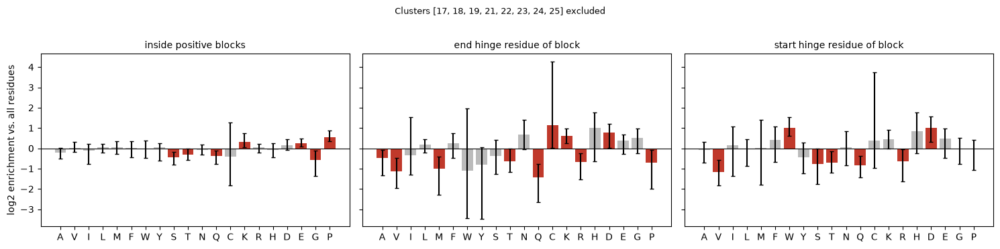

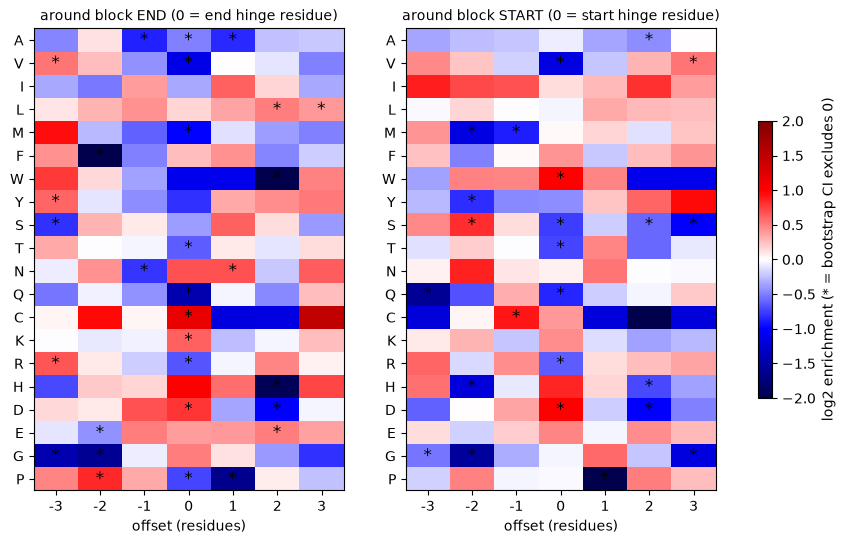

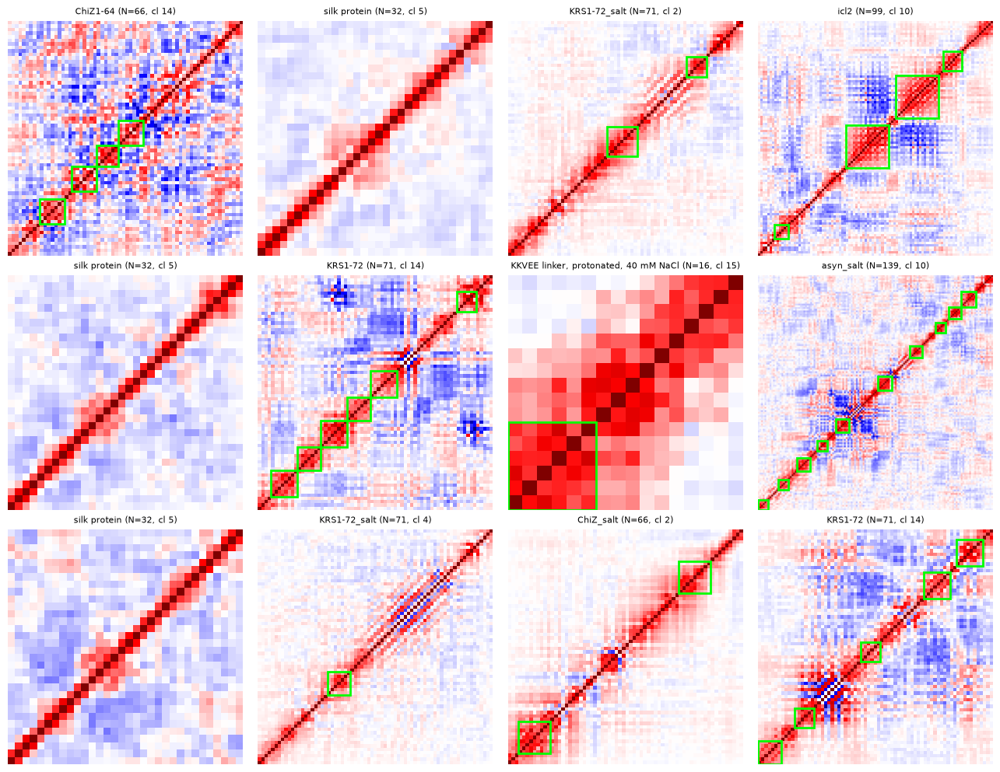

In [10]:
import re
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from collections import Counter
from scipy.signal import find_peaks

# ---------- settings ----------
EXCLUDE   = [17, 18, 19, 21, 22, 23, 24, 25]   # ordered cluster numbers to leave out
CLUSTER_ARRAY = final                          # ordered labels, one per entry in mats
W         = 5       # half-window (residues) for the boundary score
BOUND_THR = 0.30    # a boundary needs left-right cross-correlation below this
PROM      = 0.0     # ... and must stand out from its surroundings by at least this much
MIN_LEN   = 6       # minimum block length (residues)
POS_MEAN  = 0.2     # block is 'positive' if its mean off-band correlation (|i-j|>=2) exceeds this
OFFS      = list(range(-3, 4))   # offsets around block ends/starts
BOOT      = 500     # bootstrap resamples (over proteins)
PREFIX    = 'posblocks_excl_'

AA    = 'ACDEFGHIKLMNPQRSTVWY'
AAIDX = {a: i for i, a in enumerate(AA)}
ORDER = 'AVILMFWYSTNQCKRHDEGP'                       # display order, grouped by class
CLASSES = {'aliphatic AVILM': 'AVILM', 'aromatic FWY': 'FWY', 'polar STNQC': 'STNQC',
           'positive KRH': 'KRH', 'negative DE': 'DE', 'Gly': 'G', 'Pro': 'P'}
PROJ = np.zeros((20, len(CLASSES)))
for j, s in enumerate(CLASSES.values()):
    for a in s:
        PROJ[AAIDX[a], j] = 1

# ---------- sequences, aligned with mats via the png path ----------
def get_seq(system):
    try:
        s = system['COMPOSITION']['PROTEIN']['SEQUENCE']
    except (KeyError, TypeError):
        return None
    if isinstance(s, (list, tuple)):
        s = ''.join(s)
    s = re.sub('[^A-Za-z]', '', str(s)).upper()
    return s or None

seq_by_png = {databankPath + 'Data/Simulations/' + s['path'] + PNG_NAME: get_seq(s) for s in systems}
seqs = [seq_by_png.get(p) for p in paths_png]

# matrix index = Calpha pair, so sequence length = matrix size + 1
ok = np.array([s is not None and len(s) == len(M) + 1 for s, M in zip(seqs, mats)])
print(f'{ok.sum()} of {len(mats)} simulations have a sequence matching the matrix size')
bad = Counter((len(M) + 1 - len(s)) if s else 'no sequence' for s, M, o in zip(seqs, mats, ok) if not o)
if bad:
    print('mismatches (matrix size + 1 - sequence length):', dict(bad))
if not ok.any():
    raise RuntimeError('No sequence matches its matrix size; check how matrix indices map to residues')

# ---------- exclude clusters ----------
CLUSTER_ARRAY = np.asarray(CLUSTER_ARRAY)
assert len(CLUSTER_ARRAY) == len(mats), \
    f'cluster labels ({len(CLUSTER_ARRAY)}) do not match mats ({len(mats)}); use the labels of this data set'
keep = ok & ~np.isin(CLUSTER_ARRAY, EXCLUDE)
sim_idx = np.where(keep)[0]
print(f'{ok.sum()} simulations with matching sequence -> {len(sim_idx)} after excluding clusters {EXCLUDE}')
print('simulations per remaining cluster:',
      dict(sorted(zip(*np.unique(CLUSTER_ARRAY[sim_idx], return_counts=True)))))
if len(sim_idx) == 0:
    raise RuntimeError('No simulations left after exclusion')

# ---------- block detection ----------
def find_blocks(M):
    N = len(M)
    C = np.ones(N)
    for i in range(2, N - 1):                       # boundary between pair i-1 and i
        a, b = max(0, i - W), min(N, i + W)
        C[i] = M[a:i, i:b].mean()
    peaks, _ = find_peaks(-C, height=-BOUND_THR, prominence=PROM)
    edges = [0] + list(peaks) + [N]
    blocks = []
    for s, e in zip(edges[:-1], edges[1:]):
        if e - s < MIN_LEN:
            continue
        ii, jj = np.triu_indices(e - s, 2)
        m = M[s:e, s:e][ii, jj].mean()
        if m >= POS_MEAN:
            blocks.append((s, e, m))
    return blocks

# ---------- per-simulation counts ----------
K0 = OFFS.index(0)
def add(arr, seq, p):
    j = AAIDX.get(seq[p])
    if j is not None:
        arr[j] += 1

recs = []
all_c, pos_c, end_c, start_c, all_blocks = {}, {}, {}, {}, {}
for i in sim_idx:
    M, seq = mats[i], seqs[i]
    N = len(M)            # number of pairs
    NR = N + 1            # number of residues; pair k = residues (k, k+1)
    blocks = find_blocks(M)          # (s, e): pairs s..e-1  ->  residues s..e inclusive
    all_blocks[i] = blocks
    inpos = np.zeros(NR, bool)
    a = np.zeros(20); p_ = np.zeros(20)
    en = np.zeros((len(OFFS), 20)); st = np.zeros((len(OFFS), 20))
    for p in range(NR):
        add(a, seq, p)
        if any(s <= p <= e for s, e, _ in blocks):
            inpos[p] = True
            add(p_, seq, p)
    for s, e, _ in blocks:
        if e < N:                    # end residue = hinge residue e (not the chain terminus)
            for k, o in enumerate(OFFS):
                if 0 <= e + o < NR: add(en[k], seq, e + o)
        if s > 0:                    # start residue = hinge residue s
            for k, o in enumerate(OFFS):
                if 0 <= s + o < NR: add(st[k], seq, s + o)
    all_c[i], pos_c[i], end_c[i], start_c[i] = a, p_, en, st
    frac = inpos.mean()
    recs.append({'SYSTEM': names[i], 'FF': ffs[i], 'cluster': int(CLUSTER_ARRAY[i]), 'N': NR,
                 'n_blocks': len(blocks), 'pos_frac': frac,
                 'category': 'absent' if not blocks else ('whole' if frac >= 0.9 else 'partial'),
                 'blocks': ';'.join(f'{s + 1}-{e + 1}' for s, e, _ in blocks)})   # residues, 1-based, inclusive
sims = pd.DataFrame(recs)
sims.to_csv(PREFIX + 'simulations.csv', index=False)
print(sims['category'].value_counts().to_string())

# ---------- aggregate per protein ----------
prots = sorted(set(sims['SYSTEM']))
pidx = {p: k for k, p in enumerate(prots)}
P = len(prots)
pr_all, pr_pos = np.zeros((P, 20)), np.zeros((P, 20))
pr_end, pr_start = np.zeros((P, len(OFFS), 20)), np.zeros((P, len(OFFS), 20))
for i in sim_idx:
    k = pidx[names[i]]
    pr_all[k] += all_c[i]; pr_pos[k] += pos_c[i]; pr_end[k] += end_c[i]; pr_start[k] += start_c[i]
print(f'{P} proteins; {int(pr_end[:, K0].sum())} block ends, {int(pr_start[:, K0].sum())} block starts')

# ---------- enrichment with bootstrap over proteins ----------
def enrichment(obs, bg, eps=0.5):
    K = obs.shape[-1]
    fo = (obs + eps) / (obs.sum(-1, keepdims=True) + eps * K)
    fb = (bg + eps) / (bg.sum(-1, keepdims=True) + eps * K)
    return np.log2(fo / fb)

def boot_ci(p_obs, p_bg, B=BOOT, seed=0):
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(B):
        i = rng.integers(0, len(p_obs), len(p_obs))
        out.append(enrichment(p_obs[i].sum(0), p_bg[i].sum(0)))
    return np.percentile(out, [2.5, 97.5], axis=0)

def table(p_obs, p_bg, labels, proj=None):
    if proj is not None:
        p_obs, p_bg = p_obs @ proj, p_bg @ proj
    obs, bg = p_obs.sum(0), p_bg.sum(0)
    lo, hi = boot_ci(p_obs, p_bg)
    enr = enrichment(obs, bg)
    return pd.DataFrame({'count': obs.astype(int), 'freq_obs': obs / obs.sum(), 'freq_bg': bg / bg.sum(),
                         'log2_enrichment': enr, 'ci_low': lo, 'ci_high': hi,
                         'significant': (lo > 0) | (hi < 0)}, index=labels)

sets = {'inside positive blocks': pr_pos,
        'end hinge residue of block': pr_end[:, K0],
        'start hinge residue of block': pr_start[:, K0]}
tabs, ctabs = {}, {}
for name, arr in sets.items():
    tabs[name] = table(arr, pr_all, list(AA)).loc[list(ORDER)]
    ctabs[name] = table(arr, pr_all, list(CLASSES), PROJ)
    key = re.sub(r'\W+', '_', name)
    tabs[name].to_csv(PREFIX + f'aa_{key}.csv'); ctabs[name].to_csv(PREFIX + f'class_{key}.csv')
    print(f'\n=== {name} (amino acids with CI excluding 0) ===')
    t = tabs[name]; print(t[t['significant']].sort_values('log2_enrichment', ascending=False)
                          .round(3)[['count', 'freq_obs', 'freq_bg', 'log2_enrichment']].to_string())
    print(ctabs[name].round(3)[['count', 'log2_enrichment', 'ci_low', 'ci_high', 'significant']].to_string())

# ---------- figure 1: bar plots ----------
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, (name, t) in zip(axs, tabs.items()):
    y = t['log2_enrichment'].values
    ax.bar(range(20), y, yerr=[y - t['ci_low'].values, t['ci_high'].values - y], capsize=2,
           color=np.where(t['significant'], '#c0392b', '#bbbbbb'))
    ax.axhline(0, color='k', lw=0.8)
    ax.set_xticks(range(20)); ax.set_xticklabels(list(ORDER)); ax.set_title(name, fontsize=10)
axs[0].set_ylabel('log2 enrichment vs. all residues')
fig.suptitle(f'Clusters {EXCLUDE} excluded', fontsize=9, y=1.02)
plt.tight_layout(); plt.savefig(PREFIX + 'enrichment_bars.png', dpi=200, bbox_inches='tight'); plt.show()

# ---------- figure 2: position-resolved profile around block ends / starts ----------
fig, axs = plt.subplots(1, 2, figsize=(11, 6))
for ax, (title, arr) in zip(axs, [('around block END (0 = end hinge residue)', pr_end),
                                  ('around block START (0 = start hinge residue)', pr_start)]):
    obs, bg = arr.sum(0), pr_all.sum(0)
    enr = enrichment(obs, bg); lo, hi = boot_ci(arr, pr_all)
    sig = (lo > 0) | (hi < 0)
    r = [AAIDX[a] for a in ORDER]
    im = ax.imshow(enr[:, r].T, cmap='seismic', vmin=-2, vmax=2, aspect='auto')
    for y, j in enumerate(r):
        for x in range(len(OFFS)):
            if sig[x, j]:
                ax.text(x, y, '*', ha='center', va='center', fontsize=12)
    ax.set_xticks(range(len(OFFS))); ax.set_xticklabels(OFFS)
    ax.set_yticks(range(20)); ax.set_yticklabels(list(ORDER))
    ax.set_xlabel('offset (residues)'); ax.set_title(title, fontsize=10)
fig.colorbar(im, ax=axs, shrink=0.6, label='log2 enrichment (* = bootstrap CI excludes 0)')
plt.savefig(PREFIX + 'enrichment_profiles.png', dpi=200, bbox_inches='tight'); plt.show()

# ---------- figure 3: QC, detected positive blocks drawn on random maps ----------
rng = np.random.default_rng(1)
pick = rng.choice(sim_idx, min(12, len(sim_idx)), replace=False)
fig, axs = plt.subplots(3, 4, figsize=(13, 10), squeeze=False)
for a in axs.ravel():
    a.axis('off')
for a, i in zip(axs.ravel(), pick):
    a.imshow(mats[i], cmap='seismic', vmin=-1, vmax=1, origin='lower')
    for s, e, _ in all_blocks[i]:
        a.add_patch(Rectangle((s - .5, s - .5), e - s, e - s, fill=False, ec='lime', lw=2))
    a.set_title(f'{names[i]} (N={len(mats[i])}, cl {CLUSTER_ARRAY[i]})', fontsize=8)
plt.tight_layout(); plt.savefig(PREFIX + 'qc_blocks.png', dpi=150); plt.show()

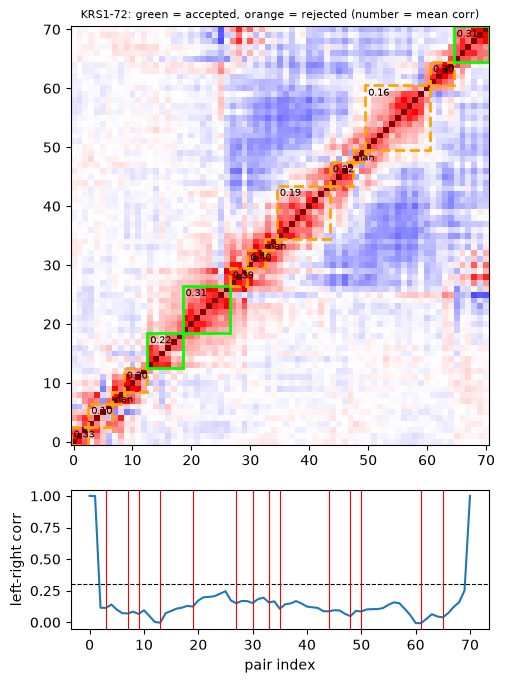

In [8]:
def debug_map(i):
    M, N = mats[i], len(mats[i])
    C = np.ones(N)
    for k in range(2, N - 1):
        C[k] = M[max(0, k - W):k, k:min(N, k + W)].mean()
    peaks, _ = find_peaks(-C, height=-BOUND_THR, prominence=PROM)
    edges = [0] + list(peaks) + [N]

    fig, (a1, a2) = plt.subplots(2, 1, figsize=(5, 7), gridspec_kw={'height_ratios': [4, 1.3]})
    a1.imshow(M, cmap='seismic', vmin=-1, vmax=1, origin='lower')
    for s, e in zip(edges[:-1], edges[1:]):
        if e - s < 2:
            continue
        ii, jj = np.triu_indices(e - s, 2)
        m = M[s:e, s:e][ii, jj].mean() if len(ii) else np.nan
        ok_ = (e - s >= MIN_LEN) and (m >= POS_MEAN)
        a1.add_patch(Rectangle((s - .5, s - .5), e - s, e - s, fill=False,
                               ec='lime' if ok_ else 'orange', lw=2, ls='-' if ok_ else '--'))
        a1.text(s, e - 1, f'{m:.2f}', fontsize=7, va='top')
    a1.set_title(f'{names[i]}: green = accepted, orange = rejected (number = mean corr)', fontsize=8)
    a2.plot(C); a2.axhline(BOUND_THR, color='k', ls='--', lw=0.8)
    for p in peaks:
        a2.axvline(p, color='r', lw=0.8)
    a2.set_ylabel('left-right corr'); a2.set_xlabel('pair index')
    plt.tight_layout(); plt.show()

debug_map(4)   # replace 0 with the index of the simulation you want to inspect

# Find least correlated amino acids

328 simulations with matching sequence -> 243 after excluding clusters [17, 18, 19, 21, 22, 23, 24, 25]
simulations per remaining cluster: {np.int64(1): np.int64(6), np.int64(2): np.int64(25), np.int64(3): np.int64(22), np.int64(4): np.int64(9), np.int64(5): np.int64(37), np.int64(6): np.int64(8), np.int64(7): np.int64(5), np.int64(8): np.int64(4), np.int64(9): np.int64(1), np.int64(10): np.int64(15), np.int64(11): np.int64(4), np.int64(12): np.int64(4), np.int64(13): np.int64(4), np.int64(14): np.int64(62), np.int64(15): np.int64(15), np.int64(16): np.int64(2), np.int64(20): np.int64(20)}
2425 terminal residues left out (TERM = 5)
amino acids dropped as rare: C F H I M W Y
               A     V    I     L    M   F   W    Y    S    T    N    Q   C     K     R    H    D     E     G     P
n_residues  1679  1115  238  1080  294  99  80  252  839  803  499  687  85  1535  1000  143  671  1744  1929  1266
n_proteins    17    31   11    13    9   6   6    9   16   16   12   17   4    29    

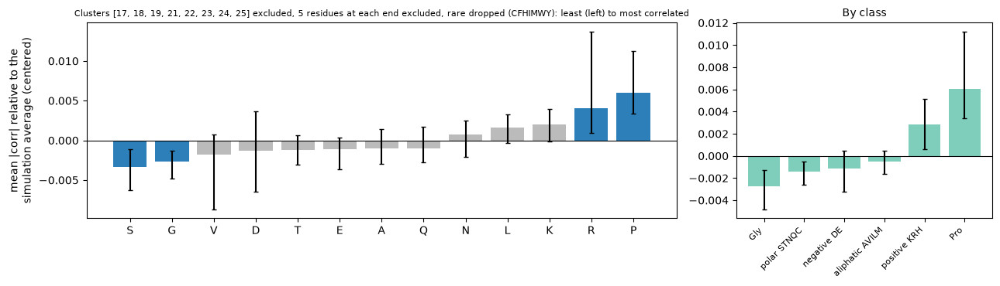

In [11]:
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# ---------- settings ----------
EXCLUDE = [17, 18, 19, 21, 22, 23, 24, 25]   # ordered cluster numbers to leave out
CLUSTER_ARRAY = final                        # ordered labels, one per entry in mats
TERM         = 5      # residues excluded at each chain end
MIN_RESIDUES = 300    # amino acids with fewer scored residues are dropped as rare
MIN_PROTEINS = 10     # ... or contributed by fewer proteins than this
RARE_MANUAL  = ''     # extra amino acids to drop by hand, e.g. 'WC'
RS_SEP  = 5      # only use correlations to pairs at least this far away in pair index
NOCORR  = 0.10   # |corr| below this counts as 'no correlation'
MIN_FAR = 8      # a pair needs at least this many far partners to be scored
BOOT    = 500
PREFIX  = 'rescorr_excl_noends_'

# ---------- select simulations ----------
CLUSTER_ARRAY = np.asarray(CLUSTER_ARRAY)
assert len(CLUSTER_ARRAY) == len(mats), \
    f'cluster labels ({len(CLUSTER_ARRAY)}) do not match mats ({len(mats)}); use the labels of this data set'

keep = ok & ~np.isin(CLUSTER_ARRAY, EXCLUDE)
sim_idx = np.where(keep)[0]
print(f'{ok.sum()} simulations with matching sequence -> {len(sim_idx)} after excluding clusters {EXCLUDE}')
print('simulations per remaining cluster:',
      dict(sorted(zip(*np.unique(CLUSTER_ARRAY[sim_idx], return_counts=True)))))

# ---------- per-residue scores ----------
def pair_metrics(M):
    N = len(M); idx = np.arange(N)
    far = np.abs(idx[:, None] - idx[None, :]) >= RS_SEP
    cnt = far.sum(1).astype(float)
    cnt_safe = np.maximum(cnt, 1)
    A = np.abs(M)
    out = {'abs':    (A * far).sum(1) / cnt_safe,
           'signed': (M * far).sum(1) / cnt_safe,
           'uncorr': (((A < NOCORR) & far).sum(1)) / cnt_safe}
    for v in out.values():
        v[cnt < MIN_FAR] = np.nan
    return out

def to_residues(v):
    """pair k = residues (k, k+1): residue r gets the mean of pairs r-1 and r."""
    st = np.vstack([np.r_[np.nan, v], np.r_[v, np.nan]])
    n = (~np.isnan(st)).sum(0)
    return np.where(n > 0, np.nansum(st, 0) / np.maximum(n, 1), np.nan)

KEYS = [('abs', True), ('abs', False), ('signed', True), ('uncorr', False)]
kname = lambda m, c: f'{m}_{"centered" if c else "raw"}'

prots = sorted(set(names[i] for i in sim_idx)); pidx = {p: k for k, p in enumerate(prots)}
S = {kname(*k): np.zeros((len(prots), 20)) for k in KEYS}
C = {kname(*k): np.zeros((len(prots), 20)) for k in KEYS}

n_term_removed = 0
for i in sim_idx:
    seq_idx = np.array([AAIDX.get(ch, -1) for ch in seqs[i]])
    NR = len(seq_idx)
    pos = np.arange(NR)
    interior = (pos >= TERM) & (pos < NR - TERM)          # leave out both chain ends
    n_term_removed += NR - interior.sum()
    pm = pair_metrics(mats[i])
    for m, cen in KEYS:
        res = to_residues(pm[m])
        res[~interior] = np.nan                            # ends are neither scored nor used for centering
        if cen:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                res = res - np.nanmean(res)
        valid = (seq_idx >= 0) & ~np.isnan(res)
        np.add.at(S[kname(m, cen)][pidx[names[i]]], seq_idx[valid], res[valid])
        np.add.at(C[kname(m, cen)][pidx[names[i]]], seq_idx[valid], 1)
print(f'{n_term_removed} terminal residues left out (TERM = {TERM})')

# ---------- drop rare amino acids ----------
Ck = C['abs_centered']
n_res  = Ck.sum(0)
n_prot = (Ck > 0).sum(0)
rare = [a for a in AA
        if n_res[AAIDX[a]] < MIN_RESIDUES or n_prot[AAIDX[a]] < MIN_PROTEINS or a in RARE_MANUAL]
kept_aa = [a for a in AA if a not in rare]
print('amino acids dropped as rare:', ' '.join(rare) if rare else 'none')
print(pd.DataFrame({'n_residues': n_res.astype(int), 'n_proteins': n_prot}, index=list(AA))
        .loc[list(ORDER)].T.to_string())

PROJ_used = PROJ.copy()
PROJ_used[[AAIDX[a] for a in rare], :] = 0               # rare residues do not enter the class averages

# ---------- summary with bootstrap over proteins ----------
def summarize(Sk, Ck, labels, proj=None, cols=None):
    if proj is not None:
        Sk, Ck = Sk @ proj, Ck @ proj
    if cols is not None:
        Sk, Ck = Sk[:, cols], Ck[:, cols]
    mean = Sk.sum(0) / np.maximum(Ck.sum(0), 1)
    rng = np.random.default_rng(0); bs = []
    for _ in range(BOOT):
        b = rng.integers(0, len(Sk), len(Sk))
        bs.append(Sk[b].sum(0) / np.maximum(Ck[b].sum(0), 1))
    lo, hi = np.percentile(bs, [2.5, 97.5], axis=0)
    return pd.DataFrame({'n_residues': Ck.sum(0).astype(int), 'mean': mean,
                         'ci_low': lo, 'ci_high': hi}, index=labels)

kcols = [AAIDX[a] for a in kept_aa]
tabs = {k: summarize(S[k], C[k], kept_aa, cols=kcols) for k in S}
ctabs = {k: summarize(S[k], C[k], list(CLASSES), PROJ_used) for k in S}
for k in ctabs:
    ctabs[k] = ctabs[k][ctabs[k].n_residues > 0]

main = tabs['abs_centered'].copy()
main['n_proteins'] = [int(n_prot[AAIDX[a]]) for a in main.index]
main['significant'] = (main.ci_low > 0) | (main.ci_high < 0)
for k in ['abs_raw', 'signed_centered', 'uncorr_raw']:
    main[k] = tabs[k]['mean']
main = main.sort_values('mean')                       # first = promotes no correlation
main['rank'] = np.arange(1, len(main) + 1)
main.to_csv(PREFIX + 'aa_ranking.csv')
for k in S:
    tabs[k].to_csv(PREFIX + f'aa_{k}.csv'); ctabs[k].to_csv(PREFIX + f'class_{k}.csv')

print(f'\nAmino acids ordered from least to most correlated '
      f'(centered mean |corr|, ends and rare residues excluded):')
print(' '.join(main.index))
print(main.round(3).to_string())
print('\nBy class:'); print(ctabs['abs_centered'].round(3).to_string())

# ---------- figure ----------
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [3, 1.3]})
y = main['mean'].values; n = len(main)
axs[0].bar(range(n), y, yerr=[y - main['ci_low'].values, main['ci_high'].values - y], capsize=2,
           color=np.where(main['significant'], '#2c7fb8', '#bbbbbb'))
axs[0].axhline(0, color='k', lw=0.8)
axs[0].set_xticks(range(n)); axs[0].set_xticklabels(main.index)
axs[0].set_ylabel('mean |corr| relative to the\nsimulation average (centered)')
axs[0].set_title(f'Clusters {EXCLUDE} excluded, {TERM} residues at each end excluded, '
                 f'rare dropped ({"".join(rare) or "none"}): least (left) to most correlated',
                 fontsize=8)

ct = ctabs['abs_centered'].sort_values('mean'); yc = ct['mean'].values
axs[1].bar(range(len(ct)), yc, yerr=[yc - ct['ci_low'].values, ct['ci_high'].values - yc], capsize=2,
           color='#7fcdbb')
axs[1].axhline(0, color='k', lw=0.8)
axs[1].set_xticks(range(len(ct))); axs[1].set_xticklabels(ct.index, rotation=45, ha='right', fontsize=8)
axs[1].set_title('By class', fontsize=10)
plt.tight_layout(); plt.savefig(PREFIX + 'ranking.png', dpi=200); plt.show()

# Find most negatively correlated amino acids

328 simulations with matching sequence -> 243 after excluding clusters [17, 18, 19, 21, 22, 23, 24, 25]
simulations per remaining cluster: {np.int64(1): np.int64(6), np.int64(2): np.int64(25), np.int64(3): np.int64(22), np.int64(4): np.int64(9), np.int64(5): np.int64(37), np.int64(6): np.int64(8), np.int64(7): np.int64(5), np.int64(8): np.int64(4), np.int64(9): np.int64(1), np.int64(10): np.int64(15), np.int64(11): np.int64(4), np.int64(12): np.int64(4), np.int64(13): np.int64(4), np.int64(14): np.int64(62), np.int64(15): np.int64(15), np.int64(16): np.int64(2), np.int64(20): np.int64(20)}
2425 terminal residues left out (TERM = 5)
amino acids dropped as rare: C F H I M W Y
               A     V    I     L    M   F   W    Y    S    T    N    Q   C     K     R    H    D     E     G     P
n_residues  1685  1121  238  1080  294  99  80  252  839  803  499  687  85  1545  1000  143  671  1748  1929  1282
n_proteins    18    33   11    13    9   6   6    9   16   16   12   17   4    33    

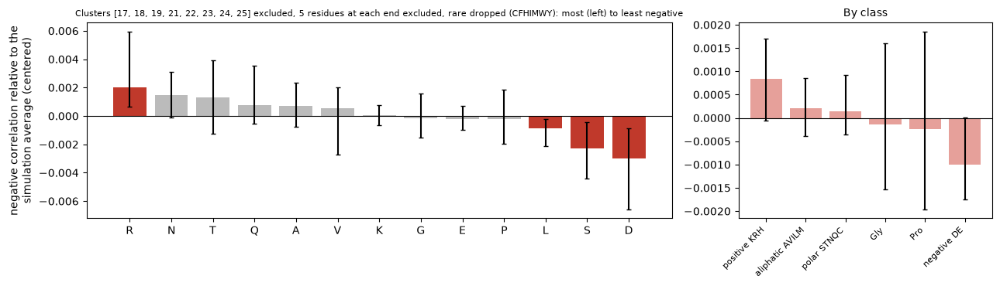

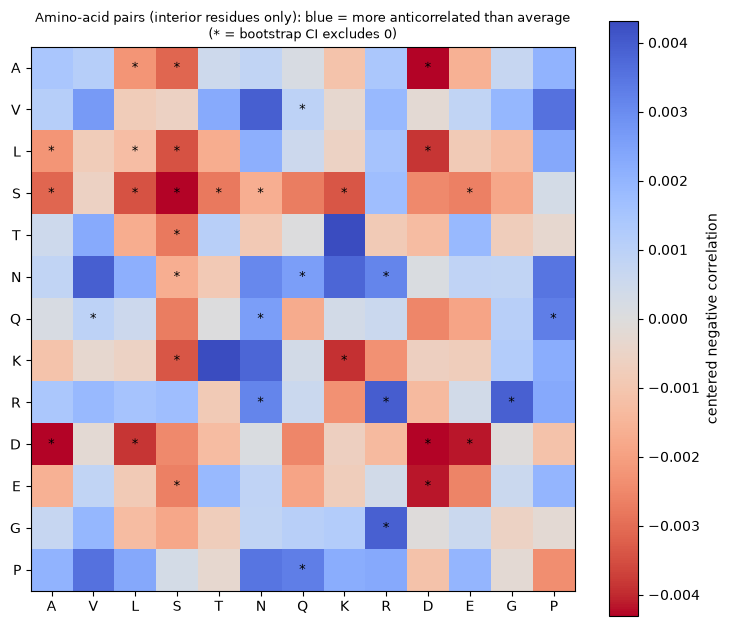

In [12]:
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# ---------- settings ----------
EXCLUDE   = [17, 18, 19, 21, 22, 23, 24, 25]   # ordered cluster numbers to leave out
CLUSTER_ARRAY = final                          # ordered labels, one per entry in mats
TERM         = 5      # residues excluded at each chain end
ENDS_AS_PARTNERS = True   # True: end residues can still be partners of interior residues
MIN_RESIDUES = 300    # amino acids with fewer scored residues are dropped as rare
MIN_PROTEINS = 10     # ... or contributed by fewer proteins than this
RARE_MANUAL  = ''     # extra amino acids to drop by hand, e.g. 'WC'
RS_SEP    = 5       # only use residue partners at least this far apart in sequence
NEG_THR   = 0.10    # R below -NEG_THR counts as a clearly negative correlation
MIN_FAR   = 8       # a residue needs at least this many far partners to be scored
MIN_PAIR  = 200     # minimum residue-pair count for an amino-acid pair to be listed
TOP_N     = 15
BOOT      = 500
PREFIX    = 'negcorr_excl_noends_'

# ---------- select simulations ----------
CLUSTER_ARRAY = np.asarray(CLUSTER_ARRAY)
assert len(CLUSTER_ARRAY) == len(mats), \
    f'cluster labels ({len(CLUSTER_ARRAY)}) do not match mats ({len(mats)}); use the labels of this data set'
keep = ok & ~np.isin(CLUSTER_ARRAY, EXCLUDE)
sim_idx = np.where(keep)[0]
print(f'{ok.sum()} simulations with matching sequence -> {len(sim_idx)} after excluding clusters {EXCLUDE}')
print('simulations per remaining cluster:',
      dict(sorted(zip(*np.unique(CLUSTER_ARRAY[sim_idx], return_counts=True)))))
if len(sim_idx) == 0:
    raise RuntimeError('No simulations left after exclusion')

prots = sorted(set(names[i] for i in sim_idx)); pidx = {p: k for k, p in enumerate(prots)}
P_ = len(prots)

# ---------- accumulate ----------
KEYS = ['neg_centered', 'neg_raw', 'frac_neg_raw', 'signed_raw']
S = {k: np.zeros((P_, 20)) for k in KEYS}
C = {k: np.zeros((P_, 20)) for k in KEYS}
Sp, Cp = np.zeros((P_, 400)), np.zeros((P_, 400))     # amino-acid pair tables

def pair_to_residue_matrix(N):
    Pm = np.zeros((N + 1, N))
    for k in range(N):
        Pm[k, k] = 1; Pm[k + 1, k] = 1
    return Pm / Pm.sum(1, keepdims=True)

pm_cache = {}
n_term_removed = 0
for i in sim_idx:
    M, N = mats[i], len(mats[i]); NR = N + 1
    if N not in pm_cache:
        pm_cache[N] = pair_to_residue_matrix(N)
    Pm = pm_cache[N]
    R = Pm @ M @ Pm.T
    seq_idx = np.array([AAIDX.get(ch, -1) for ch in seqs[i]])
    valid = seq_idx >= 0
    ar = np.arange(NR)
    interior = (ar >= TERM) & (ar < NR - TERM)            # leave out both chain ends
    n_term_removed += NR - interior.sum()

    sepok = np.abs(ar[:, None] - ar[None, :]) >= RS_SEP
    far = sepok & valid[:, None] & valid[None, :]
    if not ENDS_AS_PARTNERS:
        far = far & interior[None, :]
    if far.sum() == 0:
        continue
    cnt = far.sum(1).astype(float)
    cs = np.maximum(cnt, 1)
    neg = np.maximum(-R, 0)

    res = {'neg_raw':      (neg * far).sum(1) / cs,
           'frac_neg_raw': ((R < -NEG_THR) & far).sum(1) / cs,
           'signed_raw':   (R * far).sum(1) / cs}
    for v in res.values():
        v[cnt < MIN_FAR] = np.nan
        v[~interior] = np.nan                              # ends are neither scored nor used for centering
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        res['neg_centered'] = res['neg_raw'] - np.nanmean(res['neg_raw'])

    k = pidx[names[i]]
    for key in KEYS:
        v = res[key]; m = valid & ~np.isnan(v)
        np.add.at(S[key][k], seq_idx[m], v[m])
        np.add.at(C[key][k], seq_idx[m], 1)

    # amino-acid pair table: both residues interior, centered by the simulation mean negativity
    far_p = sepok & valid[:, None] & valid[None, :] & interior[:, None] & interior[None, :]
    if far_p.sum() == 0:
        continue
    vals = (neg - neg[far_p].mean())[far_p]
    idx = (seq_idx[:, None] * 20 + seq_idx[None, :])[far_p]
    Sp[k] += np.bincount(idx, weights=vals, minlength=400)
    Cp[k] += np.bincount(idx, minlength=400)
print(f'{n_term_removed} terminal residues left out (TERM = {TERM})')

# ---------- drop rare amino acids ----------
Ck = C['neg_centered']
n_res  = Ck.sum(0)
n_prot = (Ck > 0).sum(0)
rare = [a for a in AA
        if n_res[AAIDX[a]] < MIN_RESIDUES or n_prot[AAIDX[a]] < MIN_PROTEINS or a in RARE_MANUAL]
kept_aa = [a for a in AA if a not in rare]
print('amino acids dropped as rare:', ' '.join(rare) if rare else 'none')
print(pd.DataFrame({'n_residues': n_res.astype(int), 'n_proteins': n_prot}, index=list(AA))
        .loc[list(ORDER)].T.to_string())

PROJ_used = PROJ.copy()
PROJ_used[[AAIDX[a] for a in rare], :] = 0               # rare residues do not enter the class averages
kcols = [AAIDX[a] for a in kept_aa]

# ---------- summaries with bootstrap over proteins ----------
def summarize(Sk, Ck, labels, proj=None, cols=None):
    if proj is not None:
        Sk, Ck = Sk @ proj, Ck @ proj
    if cols is not None:
        Sk, Ck = Sk[:, cols], Ck[:, cols]
    mean = Sk.sum(0) / np.maximum(Ck.sum(0), 1)
    rng = np.random.default_rng(0); bs = []
    for _ in range(BOOT):
        b = rng.integers(0, len(Sk), len(Sk))
        bs.append(Sk[b].sum(0) / np.maximum(Ck[b].sum(0), 1))
    lo, hi = np.percentile(bs, [2.5, 97.5], axis=0)
    return pd.DataFrame({'n': Ck.sum(0).astype(int), 'mean': mean, 'ci_low': lo, 'ci_high': hi},
                        index=labels)

tabs  = {k: summarize(S[k], C[k], kept_aa, cols=kcols) for k in KEYS}
ctabs = {k: summarize(S[k], C[k], list(CLASSES), PROJ_used) for k in KEYS}
for k in ctabs:
    ctabs[k] = ctabs[k][ctabs[k].n > 0]

main = tabs['neg_centered'].copy()
main['n_proteins'] = [int(n_prot[AAIDX[a]]) for a in main.index]
main['significant'] = (main.ci_low > 0) | (main.ci_high < 0)
for k in ['neg_raw', 'frac_neg_raw', 'signed_raw']:
    main[k] = tabs[k]['mean']
main = main.sort_values('mean', ascending=False)        # first = most negatively correlated
main['rank'] = np.arange(1, len(main) + 1)
main.to_csv(PREFIX + 'aa_ranking.csv')
for k in KEYS:
    tabs[k].to_csv(PREFIX + f'aa_{k}.csv'); ctabs[k].to_csv(PREFIX + f'class_{k}.csv')

print('\nAmino acids from most to least negatively correlated '
      '(centered mean negativity, ends and rare residues excluded):')
print(' '.join(main.index))
print(main.round(4).to_string())
print('\nBy class:'); print(ctabs['neg_centered'].sort_values('mean', ascending=False).round(4).to_string())

# ---------- pair table: which amino-acid pairs are most anticorrelated ----------
cnt_p = Cp.sum(0)
mean_p = Sp.sum(0) / np.maximum(cnt_p, 1)
rng = np.random.default_rng(1); bs = []
for _ in range(BOOT):
    b = rng.integers(0, P_, P_)
    bs.append(Sp[b].sum(0) / np.maximum(Cp[b].sum(0), 1))
lo_p, hi_p = np.percentile(bs, [2.5, 97.5], axis=0)
sig_p = (lo_p > 0) | (hi_p < 0)

pairs = pd.DataFrame([{'pair': AA[a] + '-' + AA[b], 'n': int(cnt_p[a * 20 + b]),
                       'mean_centered_negativity': mean_p[a * 20 + b],
                       'ci_low': lo_p[a * 20 + b], 'ci_high': hi_p[a * 20 + b],
                       'significant': bool(sig_p[a * 20 + b])}
                      for a in range(20) for b in range(a, 20)
                      if AA[a] in kept_aa and AA[b] in kept_aa])      # no rare amino acids
pairs = pairs[pairs.n >= MIN_PAIR].sort_values('mean_centered_negativity', ascending=False)
pairs.to_csv(PREFIX + 'pairs.csv', index=False)
print(f'\nTop {TOP_N} most anticorrelated amino-acid pairs (n >= {MIN_PAIR}):')
print(pairs.head(TOP_N).round(4).to_string(index=False))

# ---------- figures ----------
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [3, 1.3]})
y = main['mean'].values; n = len(main)
axs[0].bar(range(n), y, yerr=[y - main['ci_low'].values, main['ci_high'].values - y], capsize=2,
           color=np.where(main['significant'], '#c0392b', '#bbbbbb'))
axs[0].axhline(0, color='k', lw=0.8)
axs[0].set_xticks(range(n)); axs[0].set_xticklabels(main.index)
axs[0].set_ylabel('negative correlation relative to the\nsimulation average (centered)')
axs[0].set_title(f'Clusters {EXCLUDE} excluded, {TERM} residues at each end excluded, '
                 f'rare dropped ({"".join(rare) or "none"}): most (left) to least negative', fontsize=8)
ct = ctabs['neg_centered'].sort_values('mean', ascending=False); yc = ct['mean'].values
axs[1].bar(range(len(ct)), yc, yerr=[yc - ct['ci_low'].values, ct['ci_high'].values - yc], capsize=2,
           color='#e6a09a')
axs[1].axhline(0, color='k', lw=0.8)
axs[1].set_xticks(range(len(ct))); axs[1].set_xticklabels(ct.index, rotation=45, ha='right', fontsize=8)
axs[1].set_title('By class', fontsize=10)
plt.tight_layout(); plt.savefig(PREFIX + 'ranking.png', dpi=200); plt.show()

order_k = [a for a in ORDER if a in kept_aa]
order = [AAIDX[a] for a in order_k]
Mp = mean_p.reshape(20, 20)[np.ix_(order, order)].copy()
Mp[cnt_p.reshape(20, 20)[np.ix_(order, order)] < MIN_PAIR] = np.nan
Sg = sig_p.reshape(20, 20)[np.ix_(order, order)]
vmax = np.nanpercentile(np.abs(Mp), 98)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(Mp, cmap='coolwarm_r', vmin=-vmax, vmax=vmax)    # blue = more negative than average
for a in range(len(order)):
    for b in range(len(order)):
        if Sg[a, b] and not np.isnan(Mp[a, b]):
            ax.text(b, a, '*', ha='center', va='center', fontsize=9)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order_k)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order_k)
ax.set_title('Amino-acid pairs (interior residues only): blue = more anticorrelated than average\n'
             '(* = bootstrap CI excludes 0)', fontsize=9)
fig.colorbar(im, label='centered negative correlation')
plt.tight_layout(); plt.savefig(PREFIX + 'pair_heatmap.png', dpi=200); plt.show()

328 simulations with matching sequence -> 243 after excluding clusters [17, 18, 19, 21, 22, 23, 24, 25]
simulations per remaining cluster: {np.int64(1): np.int64(6), np.int64(2): np.int64(25), np.int64(3): np.int64(22), np.int64(4): np.int64(9), np.int64(5): np.int64(37), np.int64(6): np.int64(8), np.int64(7): np.int64(5), np.int64(8): np.int64(4), np.int64(9): np.int64(1), np.int64(10): np.int64(15), np.int64(11): np.int64(4), np.int64(12): np.int64(4), np.int64(13): np.int64(4), np.int64(14): np.int64(62), np.int64(15): np.int64(15), np.int64(16): np.int64(2), np.int64(20): np.int64(20)}
2425 terminal residues left out (TERM = 5)
amino acids dropped as rare: C F H I M W Y
               A     V    I     L    M   F   W    Y    S    T    N    Q   C     K     R    H    D     E     G     P
n_residues  1685  1121  238  1080  294  99  80  252  839  803  499  687  85  1545  1000  143  671  1748  1929  1282
n_proteins    18    33   11    13    9   6   6    9   16   16   12   17   4    33    

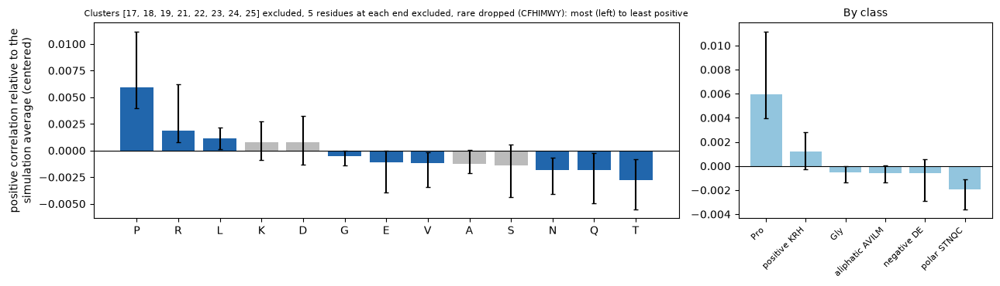

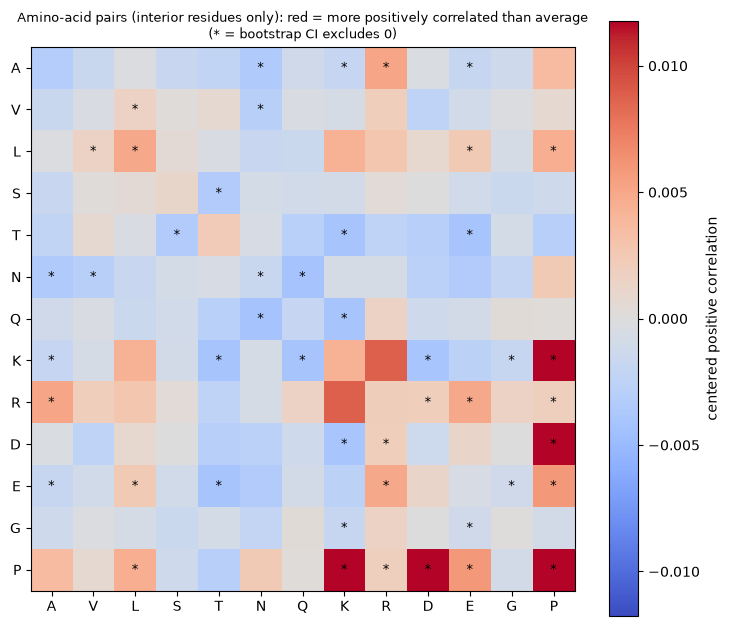

In [13]:
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# ---------- settings ----------
EXCLUDE   = [17, 18, 19, 21, 22, 23, 24, 25]   # ordered cluster numbers to leave out
CLUSTER_ARRAY = final                          # ordered labels, one per entry in mats
TERM         = 5      # residues excluded at each chain end
ENDS_AS_PARTNERS = True   # True: end residues can still be partners of interior residues
MIN_RESIDUES = 300    # amino acids with fewer scored residues are dropped as rare
MIN_PROTEINS = 10     # ... or contributed by fewer proteins than this
RARE_MANUAL  = ''     # extra amino acids to drop by hand, e.g. 'WC'
RS_SEP    = 5       # only use residue partners at least this far apart in sequence
POS_THR   = 0.10    # R above +POS_THR counts as a clearly positive correlation
MIN_FAR   = 8       # a residue needs at least this many far partners to be scored
MIN_PAIR  = 200     # minimum residue-pair count for an amino-acid pair to be listed
TOP_N     = 15
BOOT      = 500
PREFIX    = 'poscorr_excl_noends_'

# ---------- select simulations ----------
CLUSTER_ARRAY = np.asarray(CLUSTER_ARRAY)
assert len(CLUSTER_ARRAY) == len(mats), \
    f'cluster labels ({len(CLUSTER_ARRAY)}) do not match mats ({len(mats)}); use the labels of this data set'
keep = ok & ~np.isin(CLUSTER_ARRAY, EXCLUDE)
sim_idx = np.where(keep)[0]
print(f'{ok.sum()} simulations with matching sequence -> {len(sim_idx)} after excluding clusters {EXCLUDE}')
print('simulations per remaining cluster:',
      dict(sorted(zip(*np.unique(CLUSTER_ARRAY[sim_idx], return_counts=True)))))
if len(sim_idx) == 0:
    raise RuntimeError('No simulations left after exclusion')

prots = sorted(set(names[i] for i in sim_idx)); pidx = {p: k for k, p in enumerate(prots)}
P_ = len(prots)

# ---------- accumulate ----------
KEYS = ['pos_centered', 'pos_raw', 'frac_pos_raw', 'signed_raw']
S = {k: np.zeros((P_, 20)) for k in KEYS}
C = {k: np.zeros((P_, 20)) for k in KEYS}
Sp, Cp = np.zeros((P_, 400)), np.zeros((P_, 400))     # amino-acid pair tables

def pair_to_residue_matrix(N):
    Pm = np.zeros((N + 1, N))
    for k in range(N):
        Pm[k, k] = 1; Pm[k + 1, k] = 1
    return Pm / Pm.sum(1, keepdims=True)

pm_cache = {}
n_term_removed = 0
for i in sim_idx:
    M, N = mats[i], len(mats[i]); NR = N + 1
    if N not in pm_cache:
        pm_cache[N] = pair_to_residue_matrix(N)
    Pm = pm_cache[N]
    R = Pm @ M @ Pm.T
    seq_idx = np.array([AAIDX.get(ch, -1) for ch in seqs[i]])
    valid = seq_idx >= 0
    ar = np.arange(NR)
    interior = (ar >= TERM) & (ar < NR - TERM)            # leave out both chain ends
    n_term_removed += NR - interior.sum()

    sepok = np.abs(ar[:, None] - ar[None, :]) >= RS_SEP
    far = sepok & valid[:, None] & valid[None, :]
    if not ENDS_AS_PARTNERS:
        far = far & interior[None, :]
    if far.sum() == 0:
        continue
    cnt = far.sum(1).astype(float)
    cs = np.maximum(cnt, 1)
    pos = np.maximum(R, 0)

    res = {'pos_raw':      (pos * far).sum(1) / cs,
           'frac_pos_raw': ((R > POS_THR) & far).sum(1) / cs,
           'signed_raw':   (R * far).sum(1) / cs}
    for v in res.values():
        v[cnt < MIN_FAR] = np.nan
        v[~interior] = np.nan                              # ends are neither scored nor used for centering
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        res['pos_centered'] = res['pos_raw'] - np.nanmean(res['pos_raw'])

    k = pidx[names[i]]
    for key in KEYS:
        v = res[key]; m = valid & ~np.isnan(v)
        np.add.at(S[key][k], seq_idx[m], v[m])
        np.add.at(C[key][k], seq_idx[m], 1)

    # amino-acid pair table: both residues interior, centered by the simulation mean positivity
    far_p = sepok & valid[:, None] & valid[None, :] & interior[:, None] & interior[None, :]
    if far_p.sum() == 0:
        continue
    vals = (pos - pos[far_p].mean())[far_p]
    idx = (seq_idx[:, None] * 20 + seq_idx[None, :])[far_p]
    Sp[k] += np.bincount(idx, weights=vals, minlength=400)
    Cp[k] += np.bincount(idx, minlength=400)
print(f'{n_term_removed} terminal residues left out (TERM = {TERM})')

# ---------- drop rare amino acids ----------
Ck = C['pos_centered']
n_res  = Ck.sum(0)
n_prot = (Ck > 0).sum(0)
rare = [a for a in AA
        if n_res[AAIDX[a]] < MIN_RESIDUES or n_prot[AAIDX[a]] < MIN_PROTEINS or a in RARE_MANUAL]
kept_aa = [a for a in AA if a not in rare]
print('amino acids dropped as rare:', ' '.join(rare) if rare else 'none')
print(pd.DataFrame({'n_residues': n_res.astype(int), 'n_proteins': n_prot}, index=list(AA))
        .loc[list(ORDER)].T.to_string())

PROJ_used = PROJ.copy()
PROJ_used[[AAIDX[a] for a in rare], :] = 0               # rare residues do not enter the class averages
kcols = [AAIDX[a] for a in kept_aa]

# ---------- summaries with bootstrap over proteins ----------
def summarize(Sk, Ck, labels, proj=None, cols=None):
    if proj is not None:
        Sk, Ck = Sk @ proj, Ck @ proj
    if cols is not None:
        Sk, Ck = Sk[:, cols], Ck[:, cols]
    mean = Sk.sum(0) / np.maximum(Ck.sum(0), 1)
    rng = np.random.default_rng(0); bs = []
    for _ in range(BOOT):
        b = rng.integers(0, len(Sk), len(Sk))
        bs.append(Sk[b].sum(0) / np.maximum(Ck[b].sum(0), 1))
    lo, hi = np.percentile(bs, [2.5, 97.5], axis=0)
    return pd.DataFrame({'n': Ck.sum(0).astype(int), 'mean': mean, 'ci_low': lo, 'ci_high': hi},
                        index=labels)

tabs  = {k: summarize(S[k], C[k], kept_aa, cols=kcols) for k in KEYS}
ctabs = {k: summarize(S[k], C[k], list(CLASSES), PROJ_used) for k in KEYS}
for k in ctabs:
    ctabs[k] = ctabs[k][ctabs[k].n > 0]

main = tabs['pos_centered'].copy()
main['n_proteins'] = [int(n_prot[AAIDX[a]]) for a in main.index]
main['significant'] = (main.ci_low > 0) | (main.ci_high < 0)
for k in ['pos_raw', 'frac_pos_raw', 'signed_raw']:
    main[k] = tabs[k]['mean']
main = main.sort_values('mean', ascending=False)        # first = most positively correlated
main['rank'] = np.arange(1, len(main) + 1)
main.to_csv(PREFIX + 'aa_ranking.csv')
for k in KEYS:
    tabs[k].to_csv(PREFIX + f'aa_{k}.csv'); ctabs[k].to_csv(PREFIX + f'class_{k}.csv')

print('\nAmino acids from most to least positively correlated '
      '(centered mean positivity, ends and rare residues excluded):')
print(' '.join(main.index))
print(main.round(4).to_string())
print('\nBy class:'); print(ctabs['pos_centered'].sort_values('mean', ascending=False).round(4).to_string())

# ---------- pair table: which amino-acid pairs are most positively correlated ----------
cnt_p = Cp.sum(0)
mean_p = Sp.sum(0) / np.maximum(cnt_p, 1)
rng = np.random.default_rng(1); bs = []
for _ in range(BOOT):
    b = rng.integers(0, P_, P_)
    bs.append(Sp[b].sum(0) / np.maximum(Cp[b].sum(0), 1))
lo_p, hi_p = np.percentile(bs, [2.5, 97.5], axis=0)
sig_p = (lo_p > 0) | (hi_p < 0)

pairs = pd.DataFrame([{'pair': AA[a] + '-' + AA[b], 'n': int(cnt_p[a * 20 + b]),
                       'mean_centered_positivity': mean_p[a * 20 + b],
                       'ci_low': lo_p[a * 20 + b], 'ci_high': hi_p[a * 20 + b],
                       'significant': bool(sig_p[a * 20 + b])}
                      for a in range(20) for b in range(a, 20)
                      if AA[a] in kept_aa and AA[b] in kept_aa])      # no rare amino acids
pairs = pairs[pairs.n >= MIN_PAIR].sort_values('mean_centered_positivity', ascending=False)
pairs.to_csv(PREFIX + 'pairs.csv', index=False)
print(f'\nTop {TOP_N} most positively correlated amino-acid pairs (n >= {MIN_PAIR}):')
print(pairs.head(TOP_N).round(4).to_string(index=False))

# ---------- figures ----------
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [3, 1.3]})
y = main['mean'].values; n = len(main)
axs[0].bar(range(n), y, yerr=[y - main['ci_low'].values, main['ci_high'].values - y], capsize=2,
           color=np.where(main['significant'], '#2166ac', '#bbbbbb'))
axs[0].axhline(0, color='k', lw=0.8)
axs[0].set_xticks(range(n)); axs[0].set_xticklabels(main.index)
axs[0].set_ylabel('positive correlation relative to the\nsimulation average (centered)')
axs[0].set_title(f'Clusters {EXCLUDE} excluded, {TERM} residues at each end excluded, '
                 f'rare dropped ({"".join(rare) or "none"}): most (left) to least positive', fontsize=8)
ct = ctabs['pos_centered'].sort_values('mean', ascending=False); yc = ct['mean'].values
axs[1].bar(range(len(ct)), yc, yerr=[yc - ct['ci_low'].values, ct['ci_high'].values - yc], capsize=2,
           color='#92c5de')
axs[1].axhline(0, color='k', lw=0.8)
axs[1].set_xticks(range(len(ct))); axs[1].set_xticklabels(ct.index, rotation=45, ha='right', fontsize=8)
axs[1].set_title('By class', fontsize=10)
plt.tight_layout(); plt.savefig(PREFIX + 'ranking.png', dpi=200); plt.show()

order_k = [a for a in ORDER if a in kept_aa]
order = [AAIDX[a] for a in order_k]
Mp = mean_p.reshape(20, 20)[np.ix_(order, order)].copy()
Mp[cnt_p.reshape(20, 20)[np.ix_(order, order)] < MIN_PAIR] = np.nan
Sg = sig_p.reshape(20, 20)[np.ix_(order, order)]
vmax = np.nanpercentile(np.abs(Mp), 98)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(Mp, cmap='coolwarm', vmin=-vmax, vmax=vmax)      # red = more positive than average
for a in range(len(order)):
    for b in range(len(order)):
        if Sg[a, b] and not np.isnan(Mp[a, b]):
            ax.text(b, a, '*', ha='center', va='center', fontsize=9)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order_k)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order_k)
ax.set_title('Amino-acid pairs (interior residues only): red = more positively correlated than average\n'
             '(* = bootstrap CI excludes 0)', fontsize=9)
fig.colorbar(im, label='centered positive correlation')
plt.tight_layout(); plt.savefig(PREFIX + 'pair_heatmap.png', dpi=200); plt.show()

# Testing the machine learning model

In [15]:
import numpy as np
from collections import defaultdict

idx = np.where(ok)[0]
MAXD = 300

def sep_profile(M):
    N = len(M)
    return np.array([np.diag(M, d).mean() if d < N else np.nan for d in range(MAXD)])

def offdiag(M):
    iu = np.triu_indices(len(M), 1)
    return M[iu], iu

def pearson(a, b):
    return np.corrcoef(a, b)[0, 1] if a.std() > 0 and b.std() > 0 else np.nan

# split by protein
prots = sorted(set(names[i] for i in idx))
rng = np.random.default_rng(0); rng.shuffle(prots)
test_p = set(prots[:len(prots) // 5])
train = [i for i in idx if names[i] not in test_p]
test  = [i for i in idx if names[i] in test_p]

# baseline: mean correlation as a function of separation, from training simulations only
prof = np.nan_to_num(np.nanmean([sep_profile(mats[i]) for i in train], axis=0))
def baseline(M):
    iu = np.triu_indices(len(M), 1)
    return prof[np.minimum(iu[1] - iu[0], MAXD - 1)]

r_base = []
for i in test:
    y, iu = offdiag(mats[i])
    r_base.append(pearson(y, baseline(mats[i])))
print(f'baseline (separation only), held-out proteins: median r = {np.nanmedian(r_base):.3f}')

# noise ceiling: same protein and same length, different simulation (e.g. different force field)
groups = defaultdict(list)
for i in idx:
    groups[(names[i], len(mats[i]))].append(i)
r_pair = []
for g in groups.values():
    for a in range(len(g)):
        for b in range(a + 1, len(g)):
            r_pair.append(pearson(offdiag(mats[g[a]])[0], offdiag(mats[g[b]])[0]))
print(f'same protein, different simulation: median r = {np.nanmedian(r_pair):.3f} '
      f'({len(r_pair)} pairs)')

/tmp/ipykernel_24660/462787588.py:26: RuntimeWarning: Mean of empty slice
  prof = np.nan_to_num(np.nanmean([sep_profile(mats[i]) for i in train], axis=0))


baseline (separation only), held-out proteins: median r = 0.500
same protein, different simulation: median r = 0.422 (3766 pairs)


In [16]:
MIN_SEP = 5

def parts(M):
    iu = np.triu_indices(len(M), 1)
    sep = iu[1] - iu[0]
    keep = sep >= MIN_SEP
    y = M[iu][keep]
    b = prof[np.minimum(sep[keep], MAXD - 1)]
    return y, y - b

# 1) baseline quality away from the band, held-out proteins
r_b = []
for i in test:
    y, _ = parts(mats[i])
    sep = (np.triu_indices(len(mats[i]), 1)[1] - np.triu_indices(len(mats[i]), 1)[0])
    sep = sep[sep >= MIN_SEP]
    r_b.append(pearson(y, prof[np.minimum(sep, MAXD - 1)]))
print(f'baseline, |i-j|>={MIN_SEP}: median r = {np.nanmedian(r_b):.3f}')

# 2) reproducibility of the residual signal between simulations of the same protein
res = defaultdict(lambda: {'same_ff': [], 'diff_ff': []})
for (nm, N), g in groups.items():
    for a in range(len(g)):
        for b in range(a + 1, len(g)):
            _, ra = parts(mats[g[a]]); _, rb = parts(mats[g[b]])
            r = pearson(ra, rb)
            if not np.isnan(r):
                res[nm]['same_ff' if ffs[g[a]] == ffs[g[b]] else 'diff_ff'].append(r)

for kind in ['same_ff', 'diff_ff']:
    per_prot = [np.median(v[kind]) for v in res.values() if v[kind]]
    print(f'{kind}: median over proteins = {np.median(per_prot):.3f} '
          f'({len(per_prot)} proteins, {sum(len(v[kind]) for v in res.values())} pairs)')

baseline, |i-j|>=5: median r = 0.143
same_ff: median over proteins = 0.195 (15 proteins, 669 pairs)
diff_ff: median over proteins = 0.091 (12 proteins, 3097 pairs)


In [17]:
from scipy.ndimage import uniform_filter

SM = 5   # smoothing window in pairs
EXCL = [17, 18, 19, 21, 22, 23, 24, 25]
use = {i for i in idx if final[i] not in EXCL}   # drop the most ordered clusters

def resid(M, smooth):
    A = uniform_filter(M, size=smooth, mode='nearest') if smooth > 1 else M
    iu = np.triu_indices(len(M), 1); sep = iu[1] - iu[0]; k = sep >= MIN_SEP
    return A[iu][k] - prof[np.minimum(sep[k], MAXD - 1)]

for smooth in (1, SM):
    out = {'same_ff': [], 'diff_ff': []}
    for (nm, N), g in groups.items():
        g = [i for i in g if i in use]
        pr = {'same_ff': [], 'diff_ff': []}
        for a in range(len(g)):
            for b in range(a + 1, len(g)):
                r = pearson(resid(mats[g[a]], smooth), resid(mats[g[b]], smooth))
                if not np.isnan(r):
                    pr['same_ff' if ffs[g[a]] == ffs[g[b]] else 'diff_ff'].append(r)
        for k in out:
            if pr[k]: out[k].append(np.median(pr[k]))
    print(f'smoothing={smooth}: ' + ', '.join(
        f'{k} median={np.median(v):.3f} ({len(v)} proteins)' for k, v in out.items() if v))

# summary features: share of variance that is between proteins (ICC(1))
def feats(M):
    iu = np.triu_indices(len(M), 1); sep = iu[1] - iu[0]; v = M[iu][sep >= MIN_SEP]
    return [np.abs(v).mean(), (v > 0.1).mean(), (v < -0.1).mean()]

by_prot = defaultdict(list)
for i in use:
    by_prot[names[i]].append(feats(mats[i]))
by_prot = {p: np.array(v) for p, v in by_prot.items() if len(v) >= 2}
for j, fname in enumerate(['mean |corr|', 'frac > 0.1', 'frac < -0.1']):
    groups_j = [v[:, j] for v in by_prot.values()]
    n_i = np.array([len(g) for g in groups_j]); N_ = n_i.sum(); k = len(groups_j)
    grand = np.concatenate(groups_j).mean()
    msb = sum(n * (g.mean() - grand) ** 2 for n, g in zip(n_i, groups_j)) / (k - 1)
    msw = sum(((g - g.mean()) ** 2).sum() for g in groups_j) / (N_ - k)
    n0 = (N_ - (n_i ** 2).sum() / N_) / (k - 1)
    print(f'{fname}: ICC = {(msb - msw) / (msb + (n0 - 1) * msw):.2f} ({k} proteins)')

# cluster agreement within protein vs. chance
same, tot = 0, 0
for p in by_prot:
    ids = [i for i in use if names[i] == p]
    for a in range(len(ids)):
        for b in range(a + 1, len(ids)):
            same += final[ids[a]] == final[ids[b]]; tot += 1
lab = np.array([final[i] for i in use])
chance = sum((np.mean(lab == c)) ** 2 for c in np.unique(lab))
print(f'same cluster for same protein: {same / tot:.2f} (chance {chance:.2f}, {tot} pairs)')

smoothing=1: same_ff median=0.267 (16 proteins), diff_ff median=0.114 (12 proteins)
smoothing=5: same_ff median=0.468 (16 proteins), diff_ff median=0.213 (12 proteins)
mean |corr|: ICC = 0.63 (17 proteins)
frac > 0.1: ICC = 0.70 (17 proteins)
frac < -0.1: ICC = 0.13 (17 proteins)
same cluster for same protein: 0.53 (chance 0.13, 2147 pairs)


In [18]:
import pandas as pd, numpy as np

# one row per simulation: protein, force field, and the targets you want to predict
rows = []
for i in idx:
    if final[i] in EXCL: continue
    iu = np.triu_indices(len(mats[i]), 1); sep = iu[1] - iu[0]; v = mats[i][iu][sep >= 5]
    rows.append({'protein': names[i], 'ff': ffs[i], 'logN': np.log(len(mats[i]) + 1),
                 'strength': np.abs(v).mean(), 'pos_frac': (v > 0.1).mean()})
d = pd.DataFrame(rows)

# 1) average within force field first, so each force field counts once per protein
per_ff = d.groupby(['protein', 'ff'], as_index=False).mean(numeric_only=True)

# 2) FF weights: equal = option 2; raise some values to lean towards option 1
FF_WEIGHT = {}                                  # e.g. {'CHARMM36m': 1.5}; missing = 1.0
per_ff['w'] = per_ff['ff'].map(FF_WEIGHT).fillna(1.0)

def wavg(g, col):
    return np.average(g[col], weights=g['w'])

cons = per_ff.groupby('protein').apply(lambda g: pd.Series({
    'logN': g['logN'].iloc[0],
    'strength': wavg(g, 'strength'), 'pos_frac': wavg(g, 'pos_frac'),
    'strength_ffsd': g['strength'].std(ddof=0), 'pos_frac_ffsd': g['pos_frac'].std(ddof=0),
    'n_ff': len(g)}), include_groups=False)
print(cons.describe().round(3).to_string())

         logN  strength  pos_frac  strength_ffsd  pos_frac_ffsd    n_ff
count  40.000    40.000    40.000         40.000         40.000  40.000
mean    3.654     0.145     0.414          0.011          0.029   1.875
std     0.795     0.087     0.305          0.020          0.068   1.505
min     2.197     0.062     0.018          0.000          0.000   1.000
25%     3.207     0.080     0.150          0.000          0.000   1.000
50%     3.497     0.116     0.381          0.000          0.000   1.000
75%     4.306     0.162     0.549          0.021          0.038   2.000
max     5.328     0.373     1.000          0.087          0.310   5.000


In [19]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# sequence per protein
seq_of = {names[i]: seqs[i] for i in idx}
KD = dict(zip('ARNDCQEGHILKMFPSTWYV',
              [1.8,-4.5,-3.5,-3.5,2.5,-3.5,-3.5,-0.4,-3.2,4.5,3.8,-3.9,1.9,2.8,-1.6,-0.8,-0.7,-0.9,-1.3,4.2]))
def seqfeats(s):
    L = len(s); c = lambda x: sum(ch in x for ch in s) / L
    return [np.mean([KD.get(ch, 0) for ch in s]), c('KR') - c('DE'), c('KRDE'), c('G'), c('P'), c('FWY')]

P = [p for p in cons.index if p in seq_of]
X_len = cons.loc[P, ['logN']].values
X_seq = np.hstack([X_len, np.array([seqfeats(seq_of[p]) for p in P])])

for target in ['strength', 'pos_frac']:
    y = cons.loc[P, target].values
    for name, X in [('length only', X_len), ('length + composition', X_seq)]:
        m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20)))
        pred = cross_val_predict(m, X, y, cv=LeaveOneOut())
        r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        print(f'{target:9s} {name:22s} LOO R2 = {r2:.2f}, r = {np.corrcoef(y, pred)[0, 1]:.2f}')

strength  length only            LOO R2 = 0.39, r = 0.62
strength  length + composition   LOO R2 = -0.09, r = 0.34
pos_frac  length only            LOO R2 = 0.45, r = 0.67
pos_frac  length + composition   LOO R2 = 0.23, r = 0.55


In [29]:
import warnings
import numpy as np, pandas as pd
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import roc_auc_score, r2_score
from sklearn.model_selection import GroupKFold

# ---------- settings ----------
EXCLUDE = [17, 18, 19, 21, 22, 23, 24, 25]
TERM    = 1        # residues at each chain end left out of training and evaluation
RS_SEP  = 5
MIN_FAR = 8
NFOLD   = 5
BOOT    = 1000
PREFIX  = 'window_model_'

KD  = dict(zip('ARNDCQEGHILKMFPSTWYV',
               [1.8,-4.5,-3.5,-3.5,2.5,-3.5,-3.5,-0.4,-3.2,4.5,3.8,-3.9,1.9,2.8,-1.6,-0.8,-0.7,-0.9,-1.3,4.2]))
CLS = {a: j for j, s in enumerate(CLASSES.values()) for a in s}      # amino acid -> class id

# ---------- helpers ----------
def smooth(x, w):
    """windowed mean with the window clipped at the chain ends; output length == len(x)"""
    k = np.ones(2 * w + 1)
    num = np.convolve(x, k, 'full')[w:w + len(x)]
    den = np.convolve(np.ones(len(x)), k, 'full')[w:w + len(x)]
    return num / den
    
def window_feats(seq):
    arr = lambda f: np.array([f(c) for c in seq], float)
    props = {'hyd':  arr(lambda c: KD.get(c, 0.0)),
             'chg':  arr(lambda c: (c in 'KR') - (c in 'DE')),
             'fcr':  arr(lambda c: c in 'KRDE'),
             'G':    arr(lambda c: c == 'G'),
             'P':    arr(lambda c: c == 'P'),
             'arom': arr(lambda c: c in 'FWY')}
    return {f'{k}_w{w}': smooth(v, w) for k, v in props.items() for w in (3, 8)}

def coupling(M):
    N = len(M); ix = np.arange(N)
    far = np.abs(ix[:, None] - ix[None, :]) >= RS_SEP
    cnt = far.sum(1)
    v = (M * far).sum(1) / np.maximum(cnt, 1)
    v[cnt < MIN_FAR] = np.nan
    st = np.vstack([np.r_[np.nan, v], np.r_[v, np.nan]])
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        res = np.nanmean(st, 0)
        return res - np.nanmean(res)

# ---------- build the residue table ----------
use = [i for i in np.where(ok)[0] if final[i] not in EXCLUDE]
#ff_code = {f: k for k, f in enumerate(sorted(set(ffs[i] for i in use)))}
ffs_clean = [('unknown' if (f is None or str(f).strip() == '') else str(f)) for f in ffs]
ff_code = {f: k for k, f in enumerate(sorted(set(ffs_clean[i] for i in use)))}
print('force fields:', len(ff_code), '| simulations without FF label:', sum(f == 'unknown' for f in ffs_clean))
frames = []
for i in use:
    seq, M = seqs[i], mats[i]
    NR = len(seq); pos = np.arange(NR)
    inb = np.zeros(NR, bool)
    for s, e, _ in find_blocks(M):
        inb[s:e + 1] = True                              # pairs s..e-1 -> residues s..e
    d = pd.DataFrame({'protein': names[i], 'sim': i,
                      'in_block': inb.astype(int), 'coupling': coupling(M),
                      'logN': np.log(NR), 'relpos': pos / (NR - 1),
                      'dN': np.log1p(pos), 'dC': np.log1p(NR - 1 - pos),
                      #'ff': ff_code[ffs[i]],
                      'ff': ff_code[ffs_clean[i]],
                      'cls': [CLS.get(c, -1) for c in seq]})
    for k, v in window_feats(seq).items():
        d[k] = v
    d = d[(pos >= TERM) & (pos < NR - TERM) & (d['cls'] >= 0)]
    frames.append(d)
D = pd.concat(frames, ignore_index=True)
D['w'] = 1.0 / D.groupby('protein')['protein'].transform('size')   # each protein counts equally
print(f'{len(D)} residues, {D.protein.nunique()} proteins, {len(use)} simulations; '
      f'{D.in_block.mean():.0%} of residues in positive blocks')

BASE = ['logN', 'relpos', 'dN', 'dC', 'ff']
WIN  = [c for c in D.columns if '_w' in c]
SETS = {'base (length, position, FF)': BASE,
        '+ window composition':        BASE + WIN,
        '+ window + residue class':    BASE + WIN + ['cls']}

# ---------- grouped cross-validation ----------
def cv_predict(target, cols):
    kind = 'clf' if target == 'in_block' else 'reg'
    d = D.dropna(subset=[target])
    pred = np.zeros(len(d))
    cat = [c in ('ff', 'cls') for c in cols]
    for tr, te in GroupKFold(NFOLD).split(d, groups=d.protein):
        a, b = d.iloc[tr], d.iloc[te]
        kw = dict(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=50,
                  l2_regularization=1.0, categorical_features=cat, random_state=0)
        if kind == 'clf':
            m = HistGradientBoostingClassifier(**kw).fit(a[cols], a[target], sample_weight=a.w)
            pred[te] = m.predict_proba(b[cols])[:, 1]
        else:
            m = HistGradientBoostingRegressor(**kw).fit(a[cols], a[target], sample_weight=a.w)
            pred[te] = m.predict(b[cols])
    return d, pred, kind

def per_protein(d, pred, target, kind):
    out = {}
    for p, g in d.assign(pred=pred).groupby('protein'):
        y = g[target].values
        if kind == 'clf':
            if 0 < y.mean() < 1:
                out[p] = roc_auc_score(y, g.pred)
        elif y.std() > 0 and g.pred.std() > 0:
            out[p] = spearmanr(y, g.pred)[0]
    return pd.Series(out)

results, store = [], {}
for target in ['in_block', 'coupling']:
    for name, cols in SETS.items():
        d, pred, kind = cv_predict(target, cols)
        pooled = roc_auc_score(d[target], pred) if kind == 'clf' else r2_score(d[target], pred)
        pp = per_protein(d, pred, target, kind)
        store[(target, name)] = pp
        results.append({'target': target, 'model': name,
                        'pooled ' + ('AUC' if kind == 'clf' else 'R2'): round(pooled, 3),
                        'within-protein ' + ('AUC' if kind == 'clf' else 'Spearman'): round(pp.mean(), 3),
                        'n_proteins_scored': len(pp)})
res = pd.DataFrame(results)
print(res.to_string(index=False))
res.to_csv(PREFIX + 'results.csv', index=False)

# ---------- gain over the base model, bootstrapped over proteins ----------
rng = np.random.default_rng(0)
print('\nGain in the within-protein metric relative to the base model (95% bootstrap CI over proteins):')
for target in ['in_block', 'coupling']:
    b0 = store[(target, list(SETS)[0])]
    for name in list(SETS)[1:]:
        b1 = store[(target, name)]
        common = b0.index.intersection(b1.index)
        diff = (b1[common] - b0[common]).values
        bs = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(BOOT)]
        lo, hi = np.percentile(bs, [2.5, 97.5])
        flag = 'clear gain' if lo > 0 else ('worse' if hi < 0 else 'no clear difference')
        print(f'  {target:9s} {name:26s} {diff.mean():+.3f}  [{lo:+.3f}, {hi:+.3f}]  {flag}  '
              f'({len(common)} proteins)')

# ---------- which features carry the signal (permutation on held-out folds) ----------
def perm_importance(target, cols, reps=3):
    kind = 'clf' if target == 'in_block' else 'reg'
    d = D.dropna(subset=[target]).reset_index(drop=True)
    cat = [c in ('ff', 'cls') for c in cols]
    imp = {c: [] for c in cols}
    for tr, te in GroupKFold(NFOLD).split(d, groups=d.protein):
        a, b = d.iloc[tr], d.iloc[te]
        kw = dict(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=50,
                  l2_regularization=1.0, categorical_features=cat, random_state=0)
        m = (HistGradientBoostingClassifier if kind == 'clf' else HistGradientBoostingRegressor)(**kw)
        m.fit(a[cols], a[target], sample_weight=a.w)
        score = lambda X: (roc_auc_score(b[target], m.predict_proba(X)[:, 1]) if kind == 'clf'
                           else r2_score(b[target], m.predict(X)))
        s0 = score(b[cols])
        for c in cols:
            for _ in range(reps):
                X = b[cols].copy(); X[c] = rng.permutation(X[c].values)
                imp[c].append(s0 - score(X))
    return pd.Series({c: np.mean(v) for c, v in imp.items()}).sort_values(ascending=False)

full = SETS['+ window + residue class']
for target in ['in_block', 'coupling']:
    imp = perm_importance(target, full)
    print(f'\nPermutation importance for {target} (drop in score when shuffled):')
    print(imp.round(4).head(10).to_string())
    imp.to_csv(PREFIX + f'importance_{target}.csv')

D.drop(columns=['w']).to_csv(PREFIX + 'residue_table.csv', index=False)

KeyError: np.int64(0)

In [30]:
from scipy.stats import spearmanr, wilcoxon

rows = []
for p, g in D.groupby('protein'):
    for f in ['P_w8', 'chg_w8', 'fcr_w8', 'hyd_w8', 'G_w8', 'arom_w8']:
        for t in ['in_block', 'coupling']:
            if g[f].std() > 0 and g[t].std() > 0:
                rows.append((p, f, t, spearmanr(g[f], g[t])[0]))
r = pd.DataFrame(rows, columns=['protein', 'feature', 'target', 'rho'])
summ = r.groupby(['target', 'feature']).rho.agg(
    median='median', frac_positive=lambda x: (x > 0).mean(), n_proteins='size')
summ['wilcoxon_p'] = r.groupby(['target', 'feature']).rho.apply(lambda x: wilcoxon(x).pvalue)
print(summ.round(3).to_string())

# Pro robustness: drop the 5 proteins with the highest Pro content and see if P_w8 still matters
prot_pro = D.groupby('protein').P_w8.mean().sort_values(ascending=False)
print('\nPro-richest proteins:', list(prot_pro.index[:5]))

                  median  frac_positive  n_proteins  wilcoxon_p
target   feature                                               
coupling G_w8     -0.208          0.385          13       0.048
         P_w8      0.591          0.903          31       0.000
         arom_w8  -0.029          0.364          11       0.898
         chg_w8    0.325          0.688          32       0.000
         fcr_w8   -0.199          0.281          32       0.009
         hyd_w8   -0.194          0.312          32       0.005
in_block G_w8     -0.059          0.231          13       0.191
         P_w8      0.294          0.828          29       0.001
         arom_w8  -0.015          0.455          11       0.966
         chg_w8    0.103          0.677          31       0.031
         fcr_w8   -0.156          0.290          31       0.026
         hyd_w8   -0.069          0.355          31       0.111

Pro-richest proteins: ['Protein linker', 'Charged protonated sequence with CaCl', 'Charged sequence pep

In [31]:
import statsmodels.formula.api as smf

D['prot'] = D['protein']
special = ['Protein linker', 'Charged protonated sequence with CaCl', 'Charged sequence peptide',
           'Charged sequence protonated peptide', 'Charged sequence with CaCl']

def fit(data, target, label):
    d = data.copy()
    for c in ['P_w8', 'chg_w8', 'fcr_w8', 'hyd_w8', 'G_w8', 'relpos', 'dN', 'dC']:
        d[c] = d.groupby('prot')[c].transform(lambda x: (x - x.mean()) / (x.std() + 1e-9))  # within-protein z-score
    f = f'{target} ~ P_w8 + chg_w8 + fcr_w8 + hyd_w8 + G_w8 + relpos + dN + dC'
    m = smf.ols(f, d).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(d['prot'])[0]})
    print(f'\n{label}: {target}, {d.prot.nunique()} proteins')
    print(m.summary2().tables[1][['Coef.', 'Std.Err.', 'P>|z|']].round(3).to_string())

for target in ['coupling', 'in_block']:
    fit(D, target, 'all proteins')
    fit(D[~D.prot.isin(special)], target, 'without special systems')

ModuleNotFoundError: No module named 'statsmodels'

In [32]:
import numpy as np, pandas as pd
from scipy.stats import spearmanr

# ---------- settings ----------
EXCLUDE_FF = []          # custom set to drop, e.g. ['unknown', 'CHARMM36']; names as in ffs_clean
MIN_RES    = 20          # a protein needs at least this many residues to be scored
FEATS      = ['P_w8', 'chg_w8', 'fcr_w8', 'hyd_w8', 'G_w8']
TARGETS    = ['coupling', 'in_block']

inv = {k: f for f, k in ff_code.items()}
D['ff_name'] = D['ff'].map(inv)

print('simulations and proteins per force field:')
print(D.groupby('ff_name').agg(residues=('sim', 'size'), simulations=('sim', 'nunique'),
                               proteins=('protein', 'nunique')).to_string())

# ---------- within-protein test ----------
def within_protein(d):
    rows = []
    for p, g in d.groupby('protein'):
        if len(g) < MIN_RES:
            continue
        for f in FEATS:
            for t in TARGETS:
                if g[f].std() > 0 and g[t].std() > 0:
                    rows.append((p, f, t, spearmanr(g[f], g[t])[0]))
    r = pd.DataFrame(rows, columns=['protein', 'feature', 'target', 'rho'])
    return r.groupby(['target', 'feature']).rho.agg(
        median='median', frac_pos=lambda x: (x > 0).mean(), n='size')

scenarios = {'all force fields': D}
for f in sorted(D.ff_name.unique()):
    scenarios[f'without {f}'] = D[D.ff_name != f]
if EXCLUDE_FF:
    scenarios[f'without {EXCLUDE_FF}'] = D[~D.ff_name.isin(EXCLUDE_FF)]

res = {name: within_protein(d) for name, d in scenarios.items()}

for t in TARGETS:
    for stat in ['median', 'frac_pos', 'n']:
        tab = pd.DataFrame({name: r.loc[t][stat] for name, r in res.items()}).T
        print(f'\n{t}: {stat} of the within-protein Spearman rho')
        print(tab.round(2).to_string())

pd.concat(res, names=['scenario']).to_csv('ff_exclusion_within_protein.csv')

simulations and proteins per force field:
                residues  simulations  proteins
ff_name                                        
AMBER03WS           4857           79        32
AMBER99SB-DISP      3744           46         9
AMBER99SBWS         3860           49         9
CHARMM36M            674           11         5
DESAMBER            2665           49        19
unknown              296            2         2

coupling: median of the within-protein Spearman rho
feature                 G_w8  P_w8  chg_w8  fcr_w8  hyd_w8
all force fields       -0.21  0.65    0.25   -0.33   -0.18
without AMBER03WS      -0.16  0.25   -0.09    0.02   -0.01
without AMBER99SB-DISP -0.15  0.65    0.25   -0.33   -0.18
without AMBER99SBWS    -0.20  0.65    0.25   -0.33   -0.17
without CHARMM36M      -0.21  0.65    0.28   -0.33   -0.18
without DESAMBER       -0.20  0.65    0.25   -0.33   -0.16
without unknown        -0.21  0.67    0.32   -0.42   -0.19

coupling: frac_pos of the within-protein Spearma

In [33]:
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold

BASE0 = ['logN', 'relpos', 'dN', 'dC']
WIN   = [c for c in D.columns if '_w' in c]

def model_gain(d, target, B=500, seed=0):
    d = d.dropna(subset=[target]).reset_index(drop=True)
    d['w'] = 1.0 / d.groupby('protein')['protein'].transform('size')
    use_ff = d.ff.nunique() > 1
    sets = {'base': BASE0 + (['ff'] if use_ff else []),
            'window': BASE0 + (['ff'] if use_ff else []) + WIN}
    preds = {}
    for name, cols in sets.items():
        pr = np.zeros(len(d)); cat = [c == 'ff' for c in cols]
        for tr, te in GroupKFold(5).split(d, groups=d.protein):
            a, b = d.iloc[tr], d.iloc[te]
            kw = dict(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=50,
                      l2_regularization=1.0, categorical_features=cat, random_state=0)
            if target == 'in_block':
                m = HistGradientBoostingClassifier(**kw).fit(a[cols], a[target], sample_weight=a.w)
                pr[te] = m.predict_proba(b[cols])[:, 1]
            else:
                m = HistGradientBoostingRegressor(**kw).fit(a[cols], a[target], sample_weight=a.w)
                pr[te] = m.predict(b[cols])
        preds[name] = pr
    out = {k: {} for k in preds}
    for p, g in d.groupby('protein'):
        y = g[target].values
        for k in preds:
            pk = preds[k][g.index]
            if target == 'in_block':
                if 0 < y.mean() < 1: out[k][p] = roc_auc_score(y, pk)
            elif y.std() > 0 and pk.std() > 0:
                out[k][p] = spearmanr(y, pk)[0]
    s0, s1 = pd.Series(out['base']), pd.Series(out['window'])
    common = s0.index.intersection(s1.index)
    diff = (s1[common] - s0[common]).values
    rng = np.random.default_rng(seed)
    bs = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(B)]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return s0[common].mean(), s1[common].mean(), diff.mean(), lo, hi, len(common)

rows = []
for name, d in scenarios.items():
    if d.protein.nunique() < 8:
        continue
    for t in TARGETS:
        b, w, g, lo, hi, n = model_gain(d, t)
        rows.append({'scenario': name, 'target': t, 'base': b, 'window': w,
                     'gain': g, 'ci_low': lo, 'ci_high': hi, 'proteins': n})
mg = pd.DataFrame(rows)
print('\nwithin-protein metric (AUC for in_block, Spearman for coupling):')
print(mg.round(3).to_string(index=False))
mg.to_csv('ff_exclusion_model_gain.csv', index=False)


within-protein metric (AUC for in_block, Spearman for coupling):
              scenario   target  base  window   gain  ci_low  ci_high  proteins
      all force fields coupling 0.439   0.465  0.025  -0.054    0.095        32
      all force fields in_block 0.685   0.704  0.019  -0.024    0.064        32
     without AMBER03WS coupling 0.287   0.274 -0.013  -0.049    0.027        11
     without AMBER03WS in_block 0.655   0.699  0.044   0.016    0.069        12
without AMBER99SB-DISP coupling 0.382   0.503  0.121   0.039    0.206        32
without AMBER99SB-DISP in_block 0.697   0.753  0.055   0.014    0.100        31
   without AMBER99SBWS coupling 0.404   0.502  0.098   0.012    0.191        32
   without AMBER99SBWS in_block 0.664   0.723  0.059   0.021    0.097        32
     without CHARMM36M coupling 0.387   0.416  0.029  -0.079    0.143        32
     without CHARMM36M in_block 0.682   0.700  0.019  -0.029    0.065        32
      without DESAMBER coupling 0.431   0.480  0.049  

In [34]:
import numpy as np, pandas as pd
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold

BASE    = ['logN', 'relpos', 'dN', 'dC', 'ff']
WIN     = [c for c in D.columns if '_w' in c]
TARGETS = ['in_block', 'coupling']
MIN_RES = 20
B       = 1000

def cv_preds(d, target, cols):
    w = 1.0 / d.groupby('protein')['protein'].transform('size')
    cat = [c == 'ff' for c in cols]
    pr = np.zeros(len(d))
    for tr, te in GroupKFold(5).split(d, groups=d.protein):
        kw = dict(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=50,
                  l2_regularization=1.0, categorical_features=cat, random_state=0)
        a, b = d.iloc[tr], d.iloc[te]
        if target == 'in_block':
            m = HistGradientBoostingClassifier(**kw).fit(a[cols], a[target], sample_weight=w.iloc[tr])
            pr[te] = m.predict_proba(b[cols])[:, 1]
        else:
            m = HistGradientBoostingRegressor(**kw).fit(a[cols], a[target], sample_weight=w.iloc[tr])
            pr[te] = m.predict(b[cols])
    return pr

def metric(y, p, target):
    if target == 'in_block':
        return roc_auc_score(y, p) if 0 < y.mean() < 1 else np.nan
    return spearmanr(y, p)[0] if y.std() > 0 and p.std() > 0 else np.nan

rng = np.random.default_rng(0)
rows = []
for target in TARGETS:
    d = D.dropna(subset=[target]).reset_index(drop=True)
    d['p_base'] = cv_preds(d, target, BASE)
    d['p_win']  = cv_preds(d, target, BASE + WIN)
    for f, gf in d.groupby('ff_name'):
        s0, s1 = {}, {}
        for p, g in gf.groupby('protein'):
            if len(g) < MIN_RES:
                continue
            s0[p] = metric(g[target].values, g.p_base.values, target)
            s1[p] = metric(g[target].values, g.p_win.values, target)
        s0, s1 = pd.Series(s0), pd.Series(s1)
        diff = (s1 - s0).dropna().values
        if len(diff) < 5:
            continue
        bs = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(B)]
        lo, hi = np.percentile(bs, [2.5, 97.5])
        rows.append({'target': target, 'ff': f, 'proteins': len(diff),
                     'base': s0.mean(), 'window': s1.mean(), 'gain': diff.mean(),
                     'ci_low': lo, 'ci_high': hi})
res = pd.DataFrame(rows)
print(res.round(3).to_string(index=False))
res.to_csv('ff_scored_separately.csv', index=False)

# do the two related force fields run on the same proteins?
pr = D.groupby('ff_name').protein.agg(set)
print('\nproteins shared by AMBER99SB-DISP and AMBER99SBWS:',
      len(pr['AMBER99SB-DISP'] & pr['AMBER99SBWS']), 'of', len(pr['AMBER99SB-DISP']), '/', len(pr['AMBER99SBWS']))
print('of these, also in AMBER03WS:', len(pr['AMBER99SB-DISP'] & pr['AMBER99SBWS'] & pr['AMBER03WS']))

  target             ff  proteins   base  window   gain  ci_low  ci_high
in_block      AMBER03WS        26  0.697   0.691 -0.006  -0.065    0.048
in_block AMBER99SB-DISP         9  0.483   0.619  0.136   0.068    0.216
in_block    AMBER99SBWS         8  0.533   0.644  0.112   0.050    0.176
in_block       DESAMBER         8  0.542   0.565  0.023  -0.041    0.093
coupling      AMBER03WS        28  0.414   0.516  0.102   0.017    0.179
coupling AMBER99SB-DISP         9  0.189   0.286  0.097  -0.042    0.239
coupling    AMBER99SBWS         9  0.139   0.309  0.169   0.043    0.292
coupling      CHARMM36M         5 -0.023  -0.169 -0.146  -0.275   -0.017
coupling       DESAMBER         9  0.089   0.164  0.075  -0.035    0.187

proteins shared by AMBER99SB-DISP and AMBER99SBWS: 9 of 9 / 9
of these, also in AMBER03WS: 9


In [35]:
shared = pr['AMBER99SB-DISP'] & pr['AMBER99SBWS']
print('shared proteins:', sorted(shared))

rng = np.random.default_rng(1)
rows = []
for target in TARGETS:
    d = D.dropna(subset=[target]).reset_index(drop=True)
    d['p_base'] = cv_preds(d, target, BASE)
    d['p_win']  = cv_preds(d, target, BASE + WIN)
    for f, gf in d[d.protein.isin(shared)].groupby('ff_name'):
        s0, s1 = {}, {}
        for p, g in gf.groupby('protein'):
            if len(g) >= MIN_RES:
                s0[p] = metric(g[target].values, g.p_base.values, target)
                s1[p] = metric(g[target].values, g.p_win.values, target)
        diff = (pd.Series(s1) - pd.Series(s0)).dropna().values
        if len(diff) >= 5:
            bs = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(B)]
            rows.append({'target': target, 'ff': f, 'proteins': len(diff),
                         'base': pd.Series(s0).mean(), 'window': pd.Series(s1).mean(),
                         'gain': diff.mean(), 'ci_low': np.percentile(bs, 2.5),
                         'ci_high': np.percentile(bs, 97.5)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

shared proteins: ['ChiZ1-64', 'ChiZ_salt', 'KRS1-72', 'KRS1-72_salt', 'SNAP25_noions', 'asyn', 'asyn_salt', 'icl2', 'silk protein']
  target             ff  proteins   base  window   gain  ci_low  ci_high
in_block      AMBER03WS         8  0.533   0.544  0.011  -0.048    0.058
in_block AMBER99SB-DISP         9  0.483   0.619  0.136   0.063    0.219
in_block    AMBER99SBWS         8  0.533   0.644  0.112   0.050    0.176
in_block       DESAMBER         8  0.542   0.565  0.023  -0.042    0.089
coupling      AMBER03WS         9  0.076   0.289  0.213   0.087    0.344
coupling AMBER99SB-DISP         9  0.189   0.286  0.097  -0.048    0.234
coupling    AMBER99SBWS         9  0.139   0.309  0.169   0.045    0.297
coupling      CHARMM36M         5 -0.023  -0.169 -0.146  -0.285   -0.030
coupling       DESAMBER         9  0.089   0.164  0.075  -0.040    0.198


# First actual model

12461 residues, 32 proteins, 30 groups, 174 simulations
                proteins  sims
ff_name                       
AMBER03WS             32    79
AMBER99SB-DISP         9    46
AMBER99SBWS            9    49


/tmp/ipykernel_24660/2703498384.py:44: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  g = d.grp.unique(); rng.shuffle(g)
/tmp/ipykernel_24660/2703498384.py:44: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  g = d.grp.unique(); rng.shuffle(g)
/tmp/ipykernel_24660/2703498384.py:44: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  g = d.grp.unique(); rng.shuffle(g)
/tmp/ipykernel_24660/2703498384.py:44: UserWarning: you


within-protein metric (Spearman for coupling, AUC for in_block):
  target model  proteins  groups  base  model_score  gain  ci_low  ci_high
coupling small        28      26 0.358        0.455 0.100   0.023    0.199
coupling  full        28      26 0.358        0.469 0.108   0.034    0.201
in_block small        27      25 0.694        0.728 0.032  -0.021    0.089
in_block  full        27      25 0.694        0.733 0.038  -0.012    0.089

per force field, small vs base:
  coupling  AMBER03WS       n=28  base 0.349  small 0.453  gain +0.104
  coupling  AMBER99SB-DISP  n= 9  base 0.107  small -0.074  gain -0.181
  coupling  AMBER99SBWS     n= 9  base -0.029  small 0.005  gain +0.034
  in_block  AMBER03WS       n=26  base 0.661  small 0.695  gain +0.034
  in_block  AMBER99SB-DISP  n= 9  base 0.461  small 0.557  gain +0.096
  in_block  AMBER99SBWS     n= 8  base 0.510  small 0.607  gain +0.096


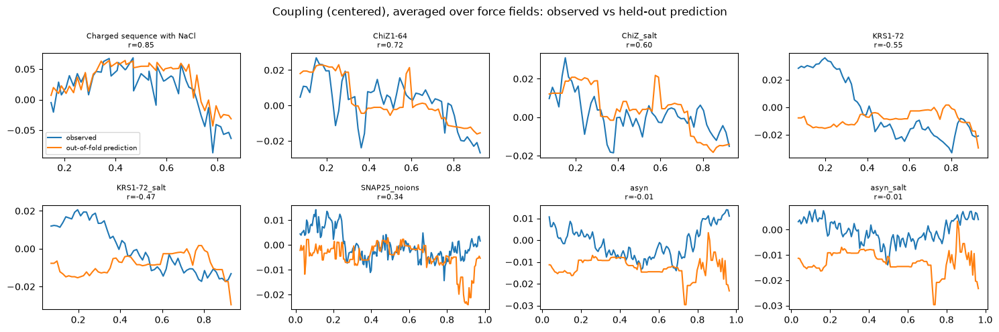

   residue  coupling  coupling_ffsd  in_block  in_block_ffsd  interior
0        G       NaN            NaN       NaN            NaN     False
1        R     0.002          0.000     0.281          0.131      True
2        G     0.001          0.000     0.281          0.131      True
3        G     0.001          0.000     0.286          0.132      True
4        L     0.001          0.000     0.324          0.160      True
5        G     0.001          0.000     0.324          0.160      True
6        G    -0.004          0.000     0.324          0.160      True
7        Q    -0.004          0.000     0.324          0.160      True
8        G     0.007          0.000     0.257          0.131      True
9        A     0.009          0.000     0.240          0.124      True
10       G    -0.004          0.000     0.195          0.091      True
11       A    -0.005          0.000     0.195          0.091      True
12       A    -0.005          0.002     0.195          0.091      True
13    

In [36]:
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import roc_auc_score

# ---------- settings ----------
KEEP    = ['AMBER99SBWS', 'AMBER03WS', 'AMBER99SB-DISP']    # force fields used for training
TARGETS = ['coupling', 'in_block']
MIN_RES = 20
NFOLD, REPEATS, B = 5, 3, 1000
PREFIX  = 'seq_model_'

BASE  = ['logN', 'relpos', 'dN', 'dC', 'ff']
SMALL = BASE + ['P_w8', 'chg_w8', 'fcr_w8', 'hyd_w8']
FULL  = BASE + [c for c in D.columns if '_w' in c]
SETS  = {'base': BASE, 'small': SMALL, 'full': FULL}

# ---------- training table ----------
T = D[D.ff_name.isin(KEEP)].copy()
T['ff'] = T.ff_name.map({f: k for k, f in enumerate(KEEP)})        # codes fixed to this list
T['grp'] = T.protein.str.replace(r'_(salt|noions)$', '', regex=True)
T['w'] = 1.0 / T.groupby('protein')['protein'].transform('size')   # every protein counts equally
print(f'{len(T)} residues, {T.protein.nunique()} proteins, {T.grp.nunique()} groups, '
      f'{T.sim.nunique()} simulations')
print(T.groupby('ff_name').agg(proteins=('protein', 'nunique'), sims=('sim', 'nunique')).to_string())

def make_model(target, cols):
    kw = dict(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=50,
              l2_regularization=1.0, categorical_features=[c == 'ff' for c in cols], random_state=0)
    return (HistGradientBoostingClassifier if target == 'in_block' else HistGradientBoostingRegressor)(**kw)

def predict(m, X, target):
    return m.predict_proba(X)[:, 1] if target == 'in_block' else m.predict(X)

def metric(y, p, target):
    if target == 'in_block':
        return roc_auc_score(y, p) if 0 < y.mean() < 1 else np.nan
    return spearmanr(y, p)[0] if y.std() > 0 and p.std() > 0 else np.nan

# ---------- repeated grouped cross-validation ----------
def oof(d, target, cols, seed):
    rng = np.random.default_rng(seed)
    g = d.grp.unique(); rng.shuffle(g)
    fold = {k: i % NFOLD for i, k in enumerate(g)}
    f = d.grp.map(fold).values
    pr = np.zeros(len(d))
    for k in range(NFOLD):
        tr, te = np.where(f != k)[0], np.where(f == k)[0]
        m = make_model(target, cols).fit(d.iloc[tr][cols], d.iloc[tr][target], sample_weight=d.w.iloc[tr])
        pr[te] = predict(m, d.iloc[te][cols], target)
    return pr

rng = np.random.default_rng(0)
rows, store, oof_pred = [], {}, {}
for t in TARGETS:
    d = T.dropna(subset=[t]).reset_index(drop=True)
    for name, cols in SETS.items():
        per_rep = []
        for r in range(REPEATS):
            pr = oof(d, t, cols, seed=r)
            if r == 0:
                oof_pred[(t, name)] = pr
            s = pd.Series({p: metric(g[t].values, pr[g.index], t)
                           for p, g in d.groupby('protein') if len(g) >= MIN_RES})
            per_rep.append(s)
        store[(t, name)] = pd.concat(per_rep, axis=1).mean(axis=1).dropna()   # average over repeats
    for name in ['small', 'full']:
        s0, s1 = store[(t, 'base')], store[(t, name)]
        df = pd.DataFrame({'b': s0, 'w': s1}).dropna()
        df['grp'] = df.index.str.replace(r'_(salt|noions)$', '', regex=True)
        gm = (df.w - df.b).groupby(df.grp).mean().values          # bootstrap over groups
        bs = [gm[rng.integers(0, len(gm), len(gm))].mean() for _ in range(B)]
        rows.append({'target': t, 'model': name, 'proteins': len(df), 'groups': len(gm),
                     'base': df.b.mean(), 'model_score': df.w.mean(), 'gain': gm.mean(),
                     'ci_low': np.percentile(bs, 2.5), 'ci_high': np.percentile(bs, 97.5)})
res = pd.DataFrame(rows)
print('\nwithin-protein metric (Spearman for coupling, AUC for in_block):')
print(res.round(3).to_string(index=False))
res.to_csv(PREFIX + 'cv_results.csv', index=False)

# ---------- per force field, for the preferred set ----------
BEST = 'small'
print(f'\nper force field, {BEST} vs base:')
for t in TARGETS:
    d = T.dropna(subset=[t]).reset_index(drop=True)
    for f, gf in d.groupby('ff_name'):
        s0 = pd.Series({p: metric(g[t].values, oof_pred[(t, 'base')][g.index], t)
                        for p, g in gf.groupby('protein') if len(g) >= MIN_RES})
        s1 = pd.Series({p: metric(g[t].values, oof_pred[(t, BEST)][g.index], t)
                        for p, g in gf.groupby('protein') if len(g) >= MIN_RES})
        dd = (s1 - s0).dropna()
        print(f'  {t:9s} {f:15s} n={len(dd):2d}  base {s0.mean():.3f}  {BEST} {s1.mean():.3f}  '
              f'gain {dd.mean():+.3f}')

# ---------- out-of-fold profiles for a few proteins ----------
t = 'coupling'
d = T.dropna(subset=[t]).reset_index(drop=True)
d['pred'] = oof_pred[(t, BEST)]
prof = d.groupby(['protein', 'relpos'])[[t, 'pred']].mean().reset_index()
show = [p for p in prof.protein.unique() if (prof.protein == p).sum() >= 30][:8]
fig, axs = plt.subplots(2, 4, figsize=(15, 5), squeeze=False)
for a, p in zip(axs.ravel(), show):
    g = prof[prof.protein == p]
    a.plot(g.relpos, g[t], label='observed'); a.plot(g.relpos, g.pred, label='out-of-fold prediction')
    a.set_title(f'{p}\nr={spearmanr(g[t], g.pred)[0]:.2f}', fontsize=8)
axs[0, 0].legend(fontsize=7)
plt.suptitle('Coupling (centered), averaged over force fields: observed vs held-out prediction')
plt.tight_layout(); plt.savefig(PREFIX + 'profiles.png', dpi=150); plt.show()

# ---------- final models on all data ----------
final = {t: make_model(t, SETS[BEST]).fit(T.dropna(subset=[t])[SETS[BEST]], T.dropna(subset=[t])[t],
                                          sample_weight=T.dropna(subset=[t]).w) for t in TARGETS}
joblib.dump({'models': final, 'cols': SETS[BEST], 'keep': KEEP, 'term': TERM}, PREFIX + 'final.joblib')

def predict_sequence(seq):
    """Per-residue predictions for a new sequence: mean over the force fields and the spread between them."""
    seq = ''.join(c for c in seq.upper() if c.isalpha())
    NR = len(seq); pos = np.arange(NR)
    base = pd.DataFrame({'logN': np.log(NR), 'relpos': pos / max(NR - 1, 1),
                         'dN': np.log1p(pos), 'dC': np.log1p(NR - 1 - pos)})
    for k, v in window_feats(seq).items():
        base[k] = v
    out = {}
    for t in TARGETS:
        P = np.column_stack([predict(final[t], base.assign(ff=k)[SETS[BEST]], t) for k in range(len(KEEP))])
        out[t] = P.mean(1); out[t + '_ffsd'] = P.std(1, ddof=1)
    out = pd.DataFrame(out); out.insert(0, 'residue', list(seq)); out['interior'] = (pos >= TERM) & (pos < NR - TERM)
    out.loc[~out.interior, [c for c in out.columns if c not in ('residue', 'interior')]] = np.nan
    return out

# example: apply to a sequence from the training set
example = next(iter({names[i]: seqs[i] for i in np.where(ok)[0]}.values()))
print(predict_sequence(example).round(3).head(15).to_string())

   residue  coupling  coupling_ffsd  in_block  in_block_ffsd  interior
0        G       NaN            NaN       NaN            NaN     False
1        R     0.002          0.000     0.281          0.131      True
2        G     0.001          0.000     0.281          0.131      True
3        G     0.001          0.000     0.286          0.132      True
4        L     0.001          0.000     0.324          0.160      True
5        G     0.001          0.000     0.324          0.160      True
6        G    -0.004          0.000     0.324          0.160      True
7        Q    -0.004          0.000     0.324          0.160      True
8        G     0.007          0.000     0.257          0.131      True
9        A     0.009          0.000     0.240          0.124      True
10       G    -0.004          0.000     0.195          0.091      True
11       A    -0.005          0.000     0.195          0.091      True
12       A    -0.005          0.002     0.195          0.091      True
13    

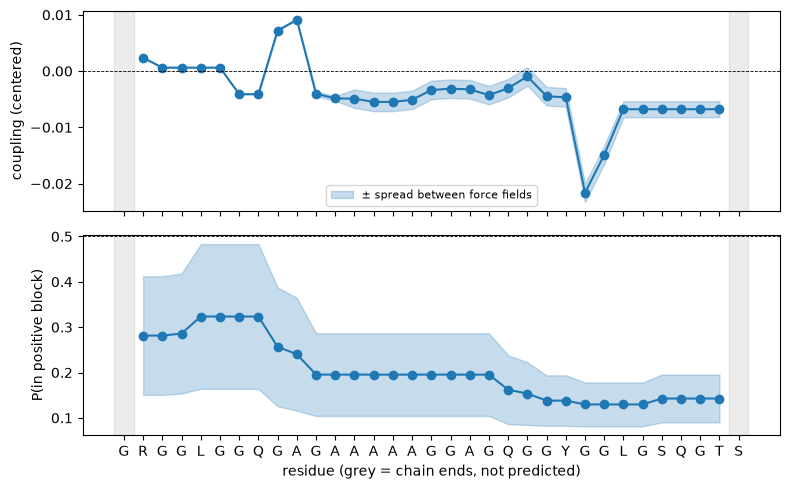

In [43]:
import numpy as np, matplotlib.pyplot as plt

seq = 'GRGGLGGQGAGAAAAAGGAGQGGYGGLGSQGTS'
pred = predict_sequence(seq)
print(pred.round(3).to_string())

x = np.arange(len(seq))
fig, axs = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for ax, t, lab in [(axs[0], 'coupling', 'coupling (centered)'),
                   (axs[1], 'in_block', 'P(in positive block)')]:
    m, s = pred[t].values, pred[t + '_ffsd'].values
    ax.plot(x, m, 'o-', color='C0')
    ax.fill_between(x, m - s, m + s, color='C0', alpha=0.25, label='± spread between force fields')
    ax.axhline(0 if t == 'coupling' else 0.5, color='k', lw=0.6, ls='--')
    ax.set_ylabel(lab)
    ax.axvspan(-0.5, TERM - 0.5, color='grey', alpha=0.15)
    ax.axvspan(len(seq) - TERM - 0.5, len(seq) - 0.5, color='grey', alpha=0.15)
axs[0].legend(fontsize=8)
axs[1].set_xticks(x); axs[1].set_xticklabels(list(seq))
axs[1].set_xlabel('residue (grey = chain ends, not predicted)')
plt.tight_layout(); plt.savefig('seq_prediction.png', dpi=200); plt.show()